Lens assertation function

In [1]:
import exifread
from pathlib import Path

def lens_id(path):
  capture_series = sorted([p for p in folder_path.iterdir() if p.suffix.lower() in [".tif", ".tiff", ".dng"]])
  focal_lengths = []
  for path in capture_series:
      with open(path, "rb") as f:
          tags = exifread.process_file(f, details=False)

          focal_length = str(tags.get("Image FocalLength", "Unknown"))
          focal_lengths.append(focal_length)
  #print(focal_lengths)
  if len(set(focal_lengths)) == 1:
      print("All images in the set came from the same camera with the same focal length.")
    
    



folder_path = Path(r"C:\Users\awpar\Desktop\EE512\calibration")
lens_id(folder_path)

All images in the set came from the same camera with the same focal length.


Item 1

In [2]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
import rawpy

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.3})
np.set_printoptions(precision=4, suppress=True)

BOARD = (9, 6)            # inner corners of the printed target
SQUARE_MM = 20.0          # measure yours with a ruler and put the real number here

CAPTURE_DIR = "calibration"   # e.g. Path.home() / "Pictures" / "calibration"


def board_object_points():
    objp = np.zeros((BOARD[0] * BOARD[1], 3), np.float32)
    objp[:, :2] = np.mgrid[0:BOARD[0], 0:BOARD[1]].T.reshape(-1, 2) * SQUARE_MM
    return objp


def from_real_images(folder):
    files = sorted(p for p in Path(folder).iterdir()
                   if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".dng"})
    obj, img, used, shape = [], [], [], None
    crit = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)
    for f in files:
        #g = cv2.imread(str(f), cv2.IMREAD_GRAYSCALE)
        g = rawpy.imread(str(f))
        if g is None:
            print("no image :(")
            continue
        raw = g.raw_image
        shape = raw.shape
        raw_bgr = cv2.cvtColor(raw, cv2.COLOR_BAYER_RG2BGR)
        raw_gray = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2GRAY)
        raw_gray = ((raw_gray-64)/(1023-64)*255).astype('uint8')
        #shape = g.shape[::-1]
        ok, corners = cv2.findChessboardCorners(
            raw_gray, BOARD, cv2.CALIB_CB_ADAPTIVE_THRESH + cv2.CALIB_CB_NORMALIZE_IMAGE)
        if not ok:
            print(f"  no corners: {f.name}")
            continue
        corners = cv2.cornerSubPix(raw_gray, corners, (11, 11), (-1, -1), crit)
        obj.append(board_object_points()); img.append(corners); used.append(f)
    return obj, img, shape, used





obj_points, img_points, img_shape, used = from_real_images(CAPTURE_DIR)
TRUTH = None
print(f"{len(img_points)} of {len(used)} captures gave a full {BOARD} grid")


rms, K, dist, rvecs, tvecs, sd_int, sd_ext, per_view = cv2.calibrateCameraExtended(
    obj_points, img_points, img_shape, None, None)

fx, fy, cy, cx = K[0, 0], K[1, 1], K[0, 2], K[1, 2]
sfx, sfy, scy, scx = sd_int.ravel()[:4]

print(f"RMS reprojection error   {rms:.4f} px\n")
print(f"f_x  {fx:9.2f}  +/- {sfx:.2f} px")
print(f"f_y  {fy:9.2f}  +/- {sfy:.2f} px")
print(f"c_x  {cx:9.2f}  +/- {scx:.2f} px      (image centre {img_shape[0]/2:.1f})")
print(f"c_y  {cy:9.2f}  +/- {scy:.2f} px      (image centre {img_shape[1]/2:.1f})")
print("\ndistortion  k1 k2 p1 p2 k3")
print("  ", dist.ravel())
print("  +/-", sd_int.ravel()[4:9])

17 of 17 captures gave a full (9, 6) grid
RMS reprojection error   0.5082 px

f_x    3491.36  +/- 3.28 px
f_y    3503.97  +/- 3.52 px
c_x    1742.99  +/- 3.30 px      (image centre 1736.0)
c_y    2305.45  +/- 3.61 px      (image centre 2312.0)

distortion  k1 k2 p1 p2 k3
   [ 0.0779 -0.2301  0.0002  0.0002  0.1916]
  +/- [0.0026 0.0104 0.0004 0.0004 0.014 ]


 Original view Row 5 Max Deviation (Before Undistortion): 0.5159 pixels
 Undistorted view Row 5 Max Deviation (After Undistortion): 0.0003 pixels


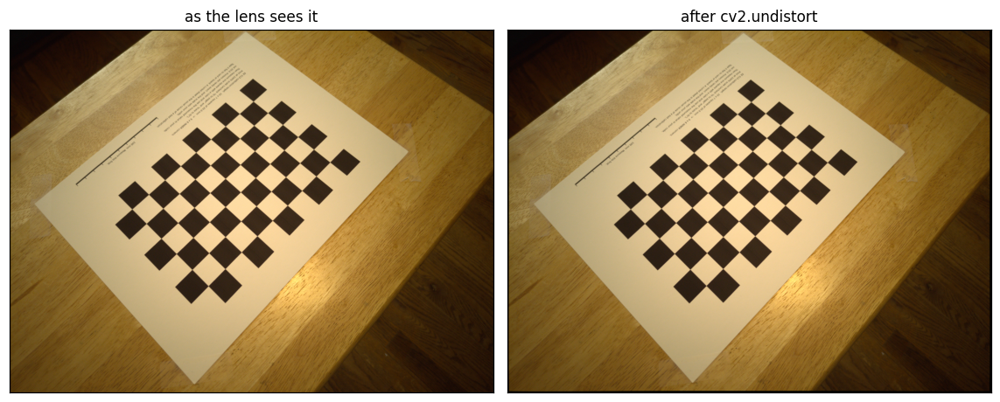

In [3]:
RAW_PATH = r"C:\Users\awpar\Desktop\EE512\calibration\capture03.dng"

Ks = K.copy()

raw= rawpy.imread(str(RAW_PATH))
view = raw.postprocess(user_flip=0)
#view = view.raw_image
#view = cv2.cvtColor(view, cv2.COLOR_BAYER_RG2BGR)
#view = cv2.cvtColor(view, cv2.COLOR_BGR2GRAY)
#view = (view/256).astype('uint8')
fixed = cv2.undistort(view, Ks, dist)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.1))
for ax, im, ttl in [(axes[0], view, "as the lens sees it"),
                    (axes[1], fixed, "after cv2.undistort")]:
    ax.imshow(im, vmin=0, vmax=1)
    ax.set_title(ttl, fontsize=11); ax.set_xticks([]); ax.set_yticks([]); ax.grid(alpha=0)
fig.tight_layout()

def board_object_points():
    objp = np.zeros((BOARD[0] * BOARD[1], 3), np.float32)
    objp[:, :2] = np.mgrid[0:BOARD[0], 0:BOARD[1]].T.reshape(-1, 2) * SQUARE_MM
    return objp

def get_corners(view, row_index):
    crit = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)
    obj, img, used, shape = [], [], [], None

    gray = cv2.cvtColor(view, cv2.COLOR_BGR2GRAY)
    
    ok, corners = cv2.findChessboardCorners(
        gray, BOARD, cv2.CALIB_CB_ADAPTIVE_THRESH + cv2.CALIB_CB_NORMALIZE_IMAGE)

    
    corners = cv2.cornerSubPix(gray, corners, (11, 11), (-1, -1), crit)
    obj.append(board_object_points()); img.append(corners); used.append(RAW_PATH)
    obj.append(board_object_points())
    img.append(corners)
    used.append(view)

    corners = img[0]  # Shape: (N, 1, 2)
    cols, rows = BOARD

    corner_grid = corners.reshape(rows, cols, 2)
    row_pts = corner_grid[row_index]  # Shape: (cols, 2) containing (x, y)
    return row_pts


def get_max_perpendicular_deviation(pts):
    x = pts[:, 0]
    y = pts[:, 1]

    # Fit a line using total least squares (cv2.fitLine)
    vx, vy, x0, y0 = cv2.fitLine(pts, cv2.DIST_L2, 0, 0.01, 0.01)

    # Convert parametric line to general form equation: Ax + By + C = 0
    A = -vy[0]
    B = vx[0]
    C = -(A * x0[0] + B * y0[0])

    # Calculate exact orthogonal distance for each point
    denominator = np.sqrt(A**2 + B**2)
    deviations = np.abs(A * x + B * y + C) / denominator

    return np.max(deviations)



row_index = 5

view_row_pts = get_corners(view, row_index)
#print(view_row_pts)
max_dev_before = get_max_perpendicular_deviation(view_row_pts)
print(
      f" Original view Row {row_index} Max Deviation (Before Undistortion):"
      f" {max_dev_before:.4f} pixels"
  )

undist_row_pts = cv2.undistortPoints(view_row_pts, Ks, dist)
undist_row_pts = undist_row_pts.squeeze(axis=1)
#print(undist_row_pts)
max_dev_after = get_max_perpendicular_deviation(undist_row_pts)
print(
      f" Undistorted view Row {row_index} Max Deviation (After Undistortion):"
      f" {max_dev_after:.4f} pixels"
  )


Item 2

In [4]:
fmm = 5.4
f35mm = 26.4
Sx = 4624
Sy = 3472
pw_datasheet = 1.6

fpx = (fx + fy)/2
pw = 1000*fmm/fpx

print(fpx)
print((sfx+sfy)/2)
print(fpx*pw_datasheet/1000)
print(((sfx+sfy)/2)*pw_datasheet/1000)

l = 0.55
N = 1.9

v_cut = 1/(l*N)
v_Nyq = 1/(4*pw)

fmm = 5.4
f35mm = 26.4
Sx = 4624
Sy = 3472



fx_datasheet = fmm / (pw_datasheet/1000)

print(f"\nPixel pitch computed through calibration: pw = {pw:.4f}")

crop = f35mm/fmm
sensor_diag = 43.3/crop
image_diag = np.sqrt((4624 ** 2) + (3473 ** 2))
pw_compare = 1000 * (sensor_diag/image_diag)

print(f"\nPixel pitch computed through f35mm: pw = {pw_compare:.4f}")

percent_dif = 100*(pw - pw_compare) / ((pw + pw_compare))/2

print(f"\nSince the calibrated pixel pitch agrees with the one computed through the f35mm to within "
f"{percent_dif:.4f} percent, I will be using the one calculated through the calibration moving forward since each lens and "
f"sensor may be slightly different from the 'ideal' datasheet part.")

percent_dif = 100*(fpx - fx_datasheet) / ((fpx + fx_datasheet)/2)

print(f"\nThe datasheet predicted fx = {fx_datasheet:.4f} px for this lens. This is within {percent_dif:.4f} percent of the "
      f"calibration value.")

3497.6648026223725
3.4026461952663185
5.5962636841957965
0.00544423391242611

Pixel pitch computed through calibration: pw = 1.5439

Pixel pitch computed through f35mm: pw = 1.5315

Since the calibrated pixel pitch agrees with the one computed through the f35mm to within 0.2010 percent, I will be using the one calculated through the calibration moving forward since each lens and sensor may be slightly different from the 'ideal' datasheet part.

The datasheet predicted fx = 3375.0000 px for this lens. This is within 3.5696 percent of the calibration value.


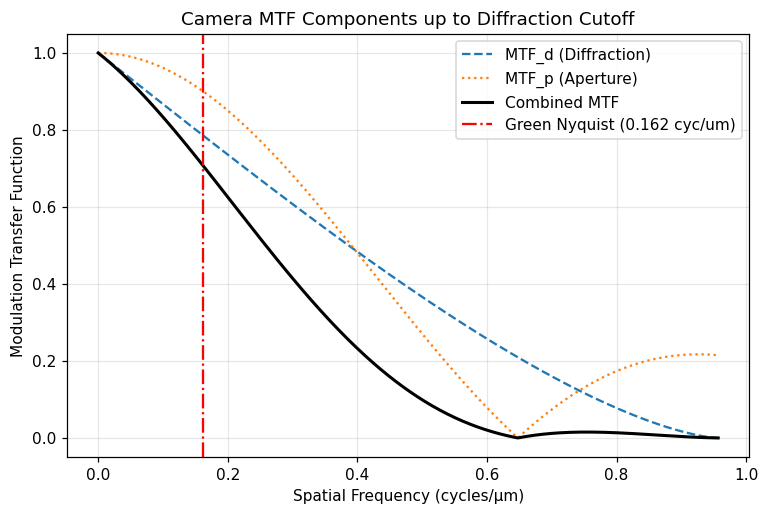

Predicted modulation at green-plane Nyquist: 0.7073

The predicted MTF50 = 0.26 lies above the Nyquist frequency, so the measured MTF50 will be set by the sampling limit of the sensor.


In [5]:
import matplotlib.pyplot as plt
import numpy as np




v = np.linspace(0, v_cut, 500)
s = v / v_cut

# Diffraction MTF
mtfd = (2 / np.pi) * (np.arccos(np.clip(s, 0, 1)) - s * np.sqrt(np.clip(1 - s**2, 0, 1)))

# Aperture MTF
mtfp = np.abs(np.sinc(v * pw))  # numpy sinc includes the pi factor: sin(pi*x)/(pi*x)

# Combined product
mtf_total = mtfd * mtfp
fifty = 0.5

# Plotting
plt.figure(figsize=(8, 5))
plt.plot(v, mtfd, label="MTF_d (Diffraction)", linestyle="--")
plt.plot(v, mtfp, label="MTF_p (Aperture)", linestyle=":")
plt.plot(v, mtf_total, label="Combined MTF", color="black", linewidth=2)
plt.axvline(
    v_Nyq,
    color="red",
    linestyle="-.",
    label=f"Green Nyquist ({v_Nyq:.3f} cyc/um)",
)

plt.title("Camera MTF Components up to Diffraction Cutoff")
plt.xlabel("Spatial Frequency (cycles/µm)")
plt.ylabel("Modulation Transfer Function")
plt.grid(True)
plt.legend()
plt.show()

mod_nyq = np.interp(v_Nyq, v, mtf_total)
print(f"Predicted modulation at green-plane Nyquist: {mod_nyq:.4f}")


def compute_mtf50(frequencies, mtf_values):
  freqs = np.asarray(frequencies)
  mtf = np.asarray(mtf_values)
  idx = np.where(mtf <= 0.5)[0][0]

  if idx == 0:
    return freqs[0]


  f1, f2 = freqs[idx - 1], freqs[idx]
  m1, m2 = mtf[idx - 1], mtf[idx]

  mtf50 = f1 + (0.5 - m1) * (f2 - f1) / (m2 - m1)
  return mtf50


MTF50 = compute_mtf50(v, mtf_total)
print(f"\nThe predicted MTF50 = {MTF50:.2f} lies above the Nyquist frequency, so the measured "
     f"MTF50 will be set by the sampling limit of the sensor.")



measured MTF50  0.1878 c/px
analytic MTF50  0.1874 c/px
difference      0.2 %


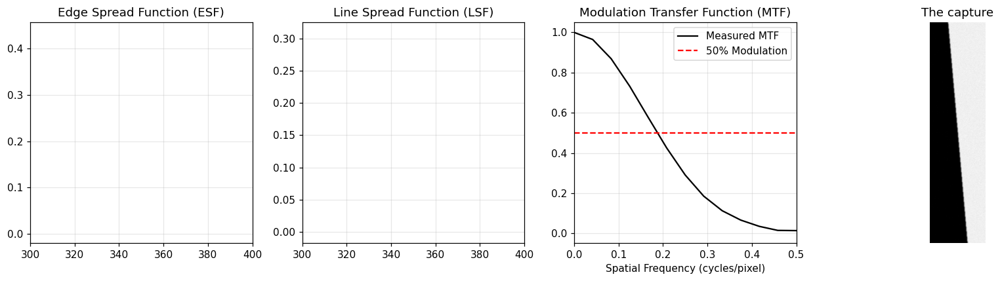

In [6]:
import sys
from pathlib import Path

# Put the shared slide helpers on the path, wherever this notebook is opened from.
for parent in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if (parent / "psu_imaging.py").exists():
        sys.path.insert(0, str(parent))
        break

import cv2
import matplotlib.pyplot as plt
import numpy as np
import psu_imaging as psu

SIGMA = 1.0          # point spread function width, in pixels

def analytic_mtf50(sigma):
    return np.sqrt(np.log(2) / (2 * np.pi ** 2 * sigma ** 2))


def capture_edge(sigma=SIGMA, angle_deg=5.0, h=512, w=128, exposure=0.55, seed=0, noisy=True):
    """A monochrome slanted-edge capture, returned in linear light."""
    scene = psu.slanted_edge(h, w, angle_deg=angle_deg)
    blurred = cv2.GaussianBlur(scene, (0, 0), sigmaX=sigma, sigmaY=sigma)
    if not noisy:
        return blurred
    raw = psu.expose_and_digitize(blurred, np.random.default_rng(seed), exposure=exposure)
    return (raw.astype(float) - psu.BLACK_LEVEL) / (psu.WHITE_LEVEL - psu.BLACK_LEVEL)





def edge_centroids(roi, window=8.0, smooth=1.5):
    """Sub-pixel edge position per row, from a windowed derivative centroid."""
    roi = np.asarray(roi, dtype=float)

    # Coarse location from a smoothed copy. Smoothing locates the edge; it never
    # touches the data we build the edge spread function from.
    smoothed = cv2.GaussianBlur(roi, (0, 0), sigmaX=smooth, sigmaY=0.01)
    coarse = np.argmax(np.abs(np.diff(smoothed, axis=1)), axis=1) + 0.5

    deriv = np.abs(np.diff(roi, axis=1))
    x = np.arange(deriv.shape[1]) + 0.5
    weight = np.where(np.abs(x[None, :] - coarse[:, None]) <= window, deriv, 0.0)

    total = weight.sum(axis=1)
    good = total > 1e-9
    centers = np.full(roi.shape[0], np.nan)
    centers[good] = (weight[good] * x).sum(axis=1) / total[good]
    return centers

def slanted_edge_mtf(roi, bin_width=0.25, window=8.0, half_support=12.0):
  """Returns (freq in cycles/px, mtf, esf_x, esf, lsf).

  half_support: Fixed distance (in pixels) from the edge center to clip the
  ESF/LSF,
                ensuring independence from total ROI width.
  """
  roi = np.asarray(roi, dtype=float)
  rows = np.arange(roi.shape[0])

  centers = edge_centroids(roi, window=window)
  ok = np.isfinite(centers)
  slope, intercept = np.polyfit(rows[ok], centers[ok], 1)
  fitted = slope * rows + intercept

  cols = np.arange(roi.shape[1])
  distance = (cols[None, :] - fitted[:, None]).ravel()
  values = roi.ravel()

  # --- OPTION 2 FIX: Enforce fixed spatial support window ---
  valid_mask = (distance >= -half_support) & (distance <= half_support)
  distance_clipped = distance[valid_mask]
  values_clipped = values[valid_mask]

  # Fixed edges range instead of distance.min() / distance.max()
  edges = np.arange(-half_support, half_support + bin_width, bin_width)
  # -----------------------------------------------------------

  idx = np.clip(np.digitize(distance_clipped, edges) - 1, 0, len(edges) - 2)
  total = np.bincount(idx, weights=values_clipped, minlength=len(edges) - 1)
  count = np.bincount(idx, minlength=len(edges) - 1)
  keep = count > 0
  esf = total[keep] / count[keep]
  esf_x = (edges[:-1] + bin_width / 2)[keep]

  lsf = np.gradient(esf, esf_x)
  lsf = lsf - np.median(np.concatenate([lsf[:5], lsf[-5:]]))
  lsf = lsf * np.hanning(len(lsf))

  spectrum = np.abs(np.fft.rfft(lsf))
  return np.fft.rfftfreq(len(lsf), d=bin_width), spectrum / spectrum[0], esf_x, esf, lsf


def mtf50(freq, mtf, freq_target=0.5):
    below = np.where(mtf < freq_target)[0]
    if len(below) == 0 or below[0] == 0:
        return np.nan
    i = below[0]
    return float(freq[i - 1] + (mtf[i - 1] - freq_target) * (freq[i] - freq[i - 1]) / (mtf[i - 1] - mtf[i]))


roi = capture_edge()
freq, mtf, esf_x, esf, lsf = slanted_edge_mtf(roi)
measured = mtf50(freq, mtf, 0.5)
expected = analytic_mtf50(SIGMA)


print(f"measured MTF50  {measured:.4f} c/px")
print(f"analytic MTF50  {expected:.4f} c/px")
print(f"difference      {abs(measured - expected) / expected * 100:.1f} %")


fig, axes = plt.subplots(1, 4, figsize=(15, 4))
axes[0].plot(esf, color="blue")
axes[0].set_title("Edge Spread Function (ESF)")
axes[0].set_xlim(300, 400)
axes[0].grid(True)

axes[1].plot(lsf, color="green")
axes[1].set_title("Line Spread Function (LSF)")
axes[1].set_xlim(300, 400)
axes[1].grid(True)

axes[2].plot(freq, mtf, color="black", label="Measured MTF")
axes[2].axhline(0.5, color="red", linestyle="--", label="50% Modulation")
axes[2].set_title("Modulation Transfer Function (MTF)")
axes[2].set_xlabel("Spatial Frequency (cycles/pixel)")
axes[2].set_xlim(0, 0.5)
axes[2].grid(True)
axes[2].legend()

axes[3].imshow(roi, cmap="gray"); plt.title("The capture"); plt.axis("off")

plt.tight_layout()
plt.show()


In [7]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
import rawpy


def extract_roi_batch_dark_square(
    folder_path, extract_green_plane=True, edge_side="left"
):
  input_dir = Path(folder_path)
  dng_files = sorted(
      [p for p in input_dir.iterdir() if p.suffix.lower() == ".dng"]
  )

  if not dng_files:
    print(f"No .dng files found in '{folder_path}'.")
    return [], []

  rois = []
  valid_files = []

  for f in dng_files:
    try:
      with rawpy.imread(str(f)) as raw:
        raw_img = raw.raw_image.astype(np.float32)

        if extract_green_plane:
          black_levels = raw.black_level_per_channel
          plane = raw_img[0::2, 1::2] - black_levels[1]
        else:
          plane = raw_img

      # 1. Blur slightly to suppress high-frequency sensor noise in dark areas
      blurred = cv2.GaussianBlur(plane, (9, 9), 0)

      # 2. Target the lowest intensity values (bottom 15% of pixel range)
      # where the very dark square lives relative to the background
      p_low = np.percentile(blurred, 15)
      mask = np.uint8((blurred <= p_low) * 255)

      # 3. Morphological cleanup to close gaps and remove small specks of noise
      kernel = np.ones((7, 7), np.uint8)
      mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
      mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

      # 4. Find contours of the isolated dark regions
      contours, _ = cv2.findContours(
          mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
      )

      best_box = None
      max_area = 0
      h_img, w_img = plane.shape

      for c in contours:
        area = cv2.contourArea(c)
        # Filter for a large shape representing the target square (> 1% of frame)
        if area > (h_img * w_img * 0.01):
          x, y, w, h = cv2.boundingRect(c)
          aspect_ratio = float(w) / h if h > 0 else 0
          if 0.5 <= aspect_ratio <= 2.0 and area > max_area:
            max_area = area
            best_box = (x, y, w, h)

      if best_box is None:
        print(
            f"Warning: Could not isolate dark square in {f.name}. Using center"
            " fallback."
        )
        bx, by, bw, bh = (
            int(w_img * 0.3),
            int(h_img * 0.3),
            int(w_img * 0.4),
            int(h_img * 0.4),
        )
      else:
        bx, by, bw, bh = best_box

      # 5. Extract edge strip for slanted-edge analysis
      margin = int(min(bw, bh) * 0.05)
      if edge_side == "left":
        ymin, ymax = by + int(bh * 0.2), by + int(bh * 0.8)
        xmin, xmax = bx - margin, bx + margin
      elif edge_side == "right":
        ymin, ymax = by + int(bh * 0.05), by + int(bh * 0.9)
        xmin, xmax = (bx + bw) - 2*margin, (bx + bw) + margin
      elif edge_side == "top":
        ymin, ymax = by - margin, by + margin
        xmin, xmax = bx + int(bw * 0.2), bx + int(bw * 0.8)
      else:  # bottom
        ymin, ymax = (by + bh) - margin, (by + bh) + margin
        xmin, xmax = bx + int(bw * 0.2), bx + int(bw * 0.8)

      # Clamp bounds to image dimensions
      ymin, ymax = max(0, ymin), min(h_img, ymax)
      xmin, xmax = max(0, xmin), min(w_img, xmax)

      roi = plane[ymin:ymax, xmin:xmax]
      rois.append(roi)
      valid_files.append(f)


      #plt.figure(figsize=(8, 8))
      #plt.imshow(roi, cmap="gray")
      #plt.colorbar(label="Linearized Intensity (DN - Black Level)")
      #plt.title(f"Extracted Green Plane (Green 1)")

    except Exception as e:
      print(f"Error processing {f.name}: {e}")

  print(
      f"Successfully extracted ROIs from {len(rois)} out of"
      f" {len(dng_files)} files."
  )
  return rois, valid_files

# Example execution:
roi_list2, file_list = extract_roi_batch_dark_square(r"C:\Users\awpar\Desktop\EE512\SlantedEdge02", extract_green_plane=True, edge_side="right")

Successfully extracted ROIs from 32 out of 32 files.


In [8]:
from pathlib import Path
import numpy as np
import rawpy




MTF50_measurements = []
MTF50c_um = []
mod_Nyq_measurements = []
v_Nyq_px = v_Nyq*2*pw

for r in roi_list2:
    freq, mtf, esf_x, esf, lsf = slanted_edge_mtf(r)
    measured = mtf50(freq, mtf)
    MTF50c_um.append(measured*(1/(2*pw)))
    MTF50_measurements.append(measured)
    #mod_Nyq = mtf50(freq, mtf, v_Nyq_px)
    mod_Nyq=np.interp(v_Nyq_px, freq, mtf)
    mod_Nyq_measurements.append(mod_Nyq)



mean = np.mean(MTF50_measurements)
std = np.std(MTF50_measurements)

mean_um = np.mean(MTF50c_um)
std_um = np.std(MTF50c_um)

mean_mod_Nyq = np.mean(mod_Nyq_measurements)
std_mod_Nyq = np.std(mod_Nyq_measurements)

roi_list, _ = extract_roi_batch_dark_square(r"C:\Users\awpar\Desktop\EE512\SlantedEdge_corner", extract_green_plane=True, edge_side="right")
freq_c, mtf_c, _, _, _ = slanted_edge_mtf(roi_list[3])
measured_corner = mtf50(freq_c, mtf_c)




print(f"\nMeasured MTF50: {mean:.2f} +- {std:.4f} cycles per green-plane pixel")
print(f"\nMeasured MTF50: {mean_um:.2f} +- {std_um:.4f} cycles per micron")
print(f"\nMeasured modulation at Nyquist frequency: {mean_mod_Nyq:.2f} +- {std_mod_Nyq:.4f}")
print(f"\nPredicted modulation at Nyquist frequency: {mod_nyq:.2f}")

print(f"\nThe measured modulation at Nyquist frequency is around half of the predicted value. The prediction "
      f"accounted for diffraction and photodiode aperture, which leaves out lens aberations like astigmatism, "
      f"spherical aberration, chromatic aberration, coma. These lens aberrations would be hard to measure seperately. "
      f"The other factor could be an optical antialiasing filter, which filters out the high frequencies to avoid aliasingl. "
      f"To test this we could image a frequency sweep in RAW to observe aliasing past the Nyquist frequency.")

print(f"\nMeasured MTF50 at corner of frame: {measured_corner:.2f} cycles per green-plane pixel")

Successfully extracted ROIs from 4 out of 4 files.

Measured MTF50: 0.31 +- 0.0037 cycles per green-plane pixel

Measured MTF50: 0.10 +- 0.0012 cycles per micron

Measured modulation at Nyquist frequency: 0.27 +- 0.0045

Predicted modulation at Nyquist frequency: 0.71

The measured modulation at Nyquist frequency is around half of the predicted value. The prediction accounted for diffraction and photodiode aperture, which leaves out lens aberations like astigmatism, spherical aberration, chromatic aberration, coma. These lens aberrations would be hard to measure seperately. The other factor could be an optical antialiasing filter, which filters out the high frequencies to avoid aliasingl. To test this we could image a frequency sweep in RAW to observe aliasing past the Nyquist frequency.

Measured MTF50 at corner of frame: 0.27 cycles per green-plane pixel


Item 3: Noise

In [9]:
import sys
from pathlib import Path

# Put the shared slide helpers on the path, wherever this notebook is opened from.
for parent in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if (parent / "psu_imaging.py").exists():
        sys.path.insert(0, str(parent))
        break

import cv2
import matplotlib.pyplot as plt
import numpy as np
import psu_imaging as psu

plt.rcParams.update(psu.figure_style())
plt.rcParams["figure.dpi"] = 110
rng = np.random.default_rng(513)
print("OpenCV", cv2.__version__, "| NumPy", np.__version__)

OpenCV 5.0.0 | NumPy 2.4.3


In [10]:
# Ground truth, known only because this is a simulation.
TRUE_K = (psu.WHITE_LEVEL - psu.BLACK_LEVEL) / psu.FULL_WELL     # DN per electron
TRUE_READ = psu.READ_NOISE                                        # electrons RMS

print(f"true conversion gain K   {TRUE_K:.4f} DN/e-")
print(f"true read noise          {TRUE_READ:.2f} e-")
print(f"true full well           {psu.FULL_WELL:.0f} e-")
print(f"black level              {psu.BLACK_LEVEL} DN, white level {psu.WHITE_LEVEL} DN")
print("\nEverything below is measured from flat fields only.")

true conversion gain K   0.4266 DN/e-
true read noise          2.80 e-
true full well           9000 e-
black level              256 DN, white level 4095 DN

Everything below is measured from flat fields only.


In [11]:
PRNU = 0.012          # 1.2 percent per-pixel gain variation, fixed for this sensor

def flat_pair(electrons, level_index):
    """Two independent frames at the same illumination."""
    patch = np.full((128, 128), electrons / psu.FULL_WELL)
    a = psu.expose_and_digitize(patch, np.random.default_rng(2 * level_index), prnu=PRNU)
    b = psu.expose_and_digitize(patch, np.random.default_rng(2 * level_index + 1), prnu=PRNU)
    return a.astype(float), b.astype(float)


levels = np.logspace(np.log10(5), np.log10(psu.FULL_WELL * 0.92), 22)
pairs = [flat_pair(e, i) for i, e in enumerate(levels)]
print(f"{len(pairs)} exposure levels, two frames each, 128 x 128 px")

#fig, axes = plt.subplots(1, 4, figsize=(11, 2.9))
#for ax, i in zip(axes, [0, 7, 14, 21]):
#    a, _ = pairs[i]
#    ax.imshow(a, cmap="gray")
#    ax.set_title(f"{levels[i]:.0f} e$^-$", fontsize=9.5)
#    ax.axis("off")
#plt.tight_layout(); plt.show()

22 exposure levels, two frames each, 128 x 128 px


In [12]:
def fit_ptc(mean, var, white_level, black_level, frac=0.7):
    """Fit the linear region, below `frac` of saturation."""
    ok = mean < (white_level - black_level) * frac
    coefficients, cov = np.polyfit(mean[ok], var[ok], 1, full=False, cov=True)
    return coefficients, ok, cov




In [13]:
means, var_single, var_pair = [], [], []
for a, b in pairs:
    means.append((a.mean() + b.mean()) / 2 - psu.BLACK_LEVEL)
    var_single.append(a.var())
    var_pair.append(np.var(a - b) / 2)

means = np.array(means); var_single = np.array(var_single); var_pair = np.array(var_pair)

coefficients, used, residuals = fit_ptc(means, var_pair, psu.WHITE_LEVEL, psu.BLACK_LEVEL)
K_hat = coefficients[0]
c_hat = coefficients[1]
read_hat = np.sqrt(max(c_hat, 0)) / K_hat
full_well_hat = (psu.WHITE_LEVEL - psu.BLACK_LEVEL) / K_hat
dr_stops = np.log2(full_well_hat / read_hat)
print(f"conversion gain   {K_hat:.4f} DN/e-     (true {TRUE_K:.4f})")
print(f"read noise        {read_hat:.2f} e-        (true {TRUE_READ:.2f})")
print(f"full well         {full_well_hat:.0f} e-       (true {psu.FULL_WELL:.0f})")
print(f"dynamic range     {dr_stops:.1f} stops")

conversion gain   0.4236 DN/e-     (true 0.4266)
read noise        2.96 e-        (true 2.80)
full well         9063 e-       (true 9000)
dynamic range     11.6 stops


In [14]:
from collections import defaultdict
from pathlib import Path
import exifread
import numpy as np
import rawpy
import pandas as pd


def process_flat_field_series(folder_path, patch_size=128):
  input_dir = Path(folder_path)
  dng_files = sorted(
      [p for p in input_dir.iterdir() if p.suffix.lower() == ".dng"]
  )

  if not dng_files:
    print(f"No DNG files found in {folder_path}")
    return [], [], []

  # 1. Read exposure settings and group files by exposure
  exposure_groups = defaultdict(list)

  for path in dng_files:
    with open(path, "rb") as f:
      tags = exifread.process_file(f, details=False)

    # Use exposure time and ISO as the key to identify matching pairs
    exp_time = str(tags.get("Image ExposureTime", "Unknown"))
    iso = str(tags.get("Image ISOSpeedRatings", "Unknown"))
    key = (exp_time, iso)

    exposure_groups[key].append(path)

  # Form pairs from files with the same exposure settings
  pairs = []
  for key, paths in exposure_groups.items():
    # Take files in chunks of 2 to form pairs
    for i in range(0, len(paths) - 1, 2):
      pairs.append((paths[i], paths[i + 1]))

  print(
      f"Found {len(dng_files)} total files, grouped into {len(pairs)} pairs"
      " with matching exposures."
  )

  means, var_single, var_pair = [], [], []

  # 2. Process each pair
  for path_a, path_b in pairs:
    with rawpy.imread(str(path_a)) as raw_a, rawpy.imread(str(path_b)) as raw_b:

      # Get black level for the green channel (assuming RGBG layout [0::2, 0::2])
      black_level = raw_a.black_level_per_channel[1] 

      # Extract Green 1 plane
      g_a = raw_a.raw_image.astype(np.float32)[0::2, 1::2]
      g_b = raw_b.raw_image.astype(np.float32)[0::2, 1::2]

      # Extract central patch (128x128) to avoid lens shading
      h, w = g_a.shape
      cy, cx = h // 2, w // 2
      half = patch_size // 2

      a = g_a[cy - half : cy + half, cx - half : cx + half]
      b = g_b[cy - half : cy + half, cx - half : cx + half]

      # 3. Compute PTC metrics using your specified loop structure
      means.append((a.mean() + b.mean()) / 2.0 - black_level)
      var_single.append(a.var(ddof=1))
      var_pair.append(np.var(a - b, ddof=1) / 2.0)

  return np.array(means), np.array(var_single), np.array(var_pair), black_level


# Example usage:
means, var_single, var_pair, black_level = process_flat_field_series("./FlatFields")
#white_level = np.max(means)
white_level = 1023

data = {
      "Pair Index": np.arange(len(means)) + 1,
      "Mean Signal (DN)": means,
      "Single-Frame Var": var_single,
      "Pair-Difference Var": var_pair,
  }

df = pd.DataFrame(data)

  # Format floating-point numbers for clean display
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

print("--- Photon Transfer Curve (PTC) Data Table ---")
print(df.to_string(index=False))

Found 36 total files, grouped into 18 pairs with matching exposures.
--- Photon Transfer Curve (PTC) Data Table ---
 Pair Index  Mean Signal (DN)  Single-Frame Var  Pair-Difference Var
          1           26.1211            2.2734               2.0591
          2           32.5406            2.5000               2.4511
          3           43.4691            3.4664               3.4014
          4           70.1246            5.5930               5.2219
          5           94.0963            7.6323               7.0148
          6          141.5776           11.2826              10.1337
          7          282.8357           24.8733              19.8500
          8          649.3152           64.9685              45.3864
          9          959.0000            0.0000               0.0000
         10          460.7844           46.4874              32.6037
         11          563.3428           50.9335              39.3481
         12           75.0580            5.9135         

conversion gain   0.0695 +- 0.0001 DN/e-     
read noise        6.94 +- 0.4365 e-        
full well         13798 e-      
dynamic range     11.0 stops. (low end defined at S/N = 1, so read noise)

conversion gain from single variance  0.0975 DN/e-     
Percent difference between single fit and pair fit: 33.5374% The difference is due to the presence of fixed pattern noise.


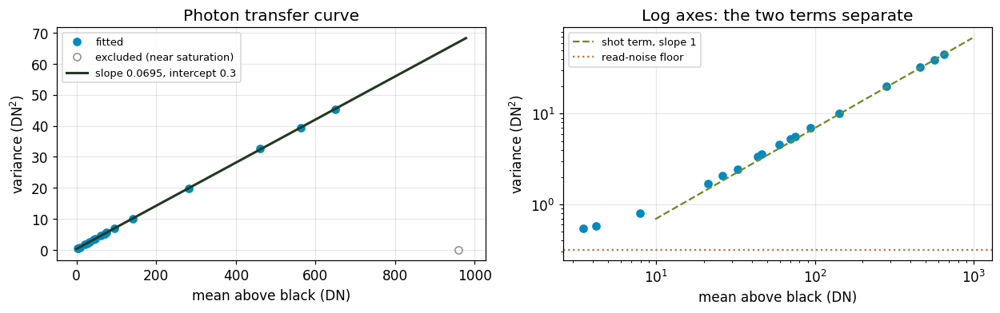

In [15]:
coefficients, used, cov = fit_ptc(means, var_pair, white_level, black_level)
K_hat = coefficients[0]
c_hat = coefficients[1]
K_hat_var = np.sqrt(cov[0,0])
c_hat_var = np.sqrt(cov[1,1])
read_hat = np.sqrt(max((c_hat-(1/12)), 0)) / K_hat
read_hat_var = c_hat_var/(2*np.sqrt(c_hat)*K_hat)
full_well_hat = (white_level - black_level) / K_hat
dr_stops = np.log2(full_well_hat / read_hat)
K_hat_single, _, _ = fit_ptc(means, var_single, white_level, black_level)
K_hat_single = K_hat_single[0]

print(f"conversion gain   {K_hat:.4f} +- {K_hat_var:.4f} DN/e-     ")
print(f"read noise        {read_hat:.2f} +- {read_hat_var:.4f} e-        ")
print(f"full well         {full_well_hat:.0f} e-      ")
print(f"dynamic range     {dr_stops:.1f} stops. (low end defined at S/N = 1, so read noise)")

print(f"\nconversion gain from single variance  {K_hat_single:.4f} DN/e-     ")
percent_dif = 100*np.abs(K_hat_single-K_hat)/((K_hat_single + K_hat)/2)
print(f"Percent difference between single fit and pair fit: {percent_dif:.4f}% The difference is due to the presence "
      f"of fixed pattern noise.")

#print(cov)


fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.7))
xs = np.linspace(0, means.max() * 1.02, 100)

axes[0].plot(means[used], var_pair[used], "o", ms=6, color=psu.PSU_BLUE, label="fitted")
axes[0].plot(means[~used], var_pair[~used], "o", ms=6, mfc="none",
             color=psu.PSU_GRAY, label="excluded (near saturation)")
axes[0].plot(xs, K_hat * xs + c_hat, "-", lw=2, color=psu.PSU_FOREST,
             label=f"slope {K_hat:.4f}, intercept {c_hat:.1f}")
axes[0].set_xlabel("mean above black (DN)"); axes[0].set_ylabel("variance (DN$^2$)")
axes[0].set_title("Photon transfer curve"); axes[0].legend(fontsize=8.5)

axes[1].loglog(means, var_pair, "o", ms=6, color=psu.PSU_BLUE)
axes[1].loglog(xs[1:], K_hat * xs[1:], "--", lw=1.5, color=psu.PSU_GREEN,
               label="shot term, slope 1")
axes[1].axhline(c_hat, ls=":", lw=1.5, color=psu.PSU_WARM, label="read-noise floor")
axes[1].set_xlabel("mean above black (DN)"); axes[1].set_ylabel("variance (DN$^2$)")
axes[1].set_title("Log axes: the two terms separate"); axes[1].legend(fontsize=8.5)
plt.tight_layout(); plt.show()

C:\Users\awpar\AppData\Local\Temp\ipykernel_22680\1749558746.py:18: RuntimeWarning: divide by zero encountered in divide
  snr_measured = mu_e / noise_e


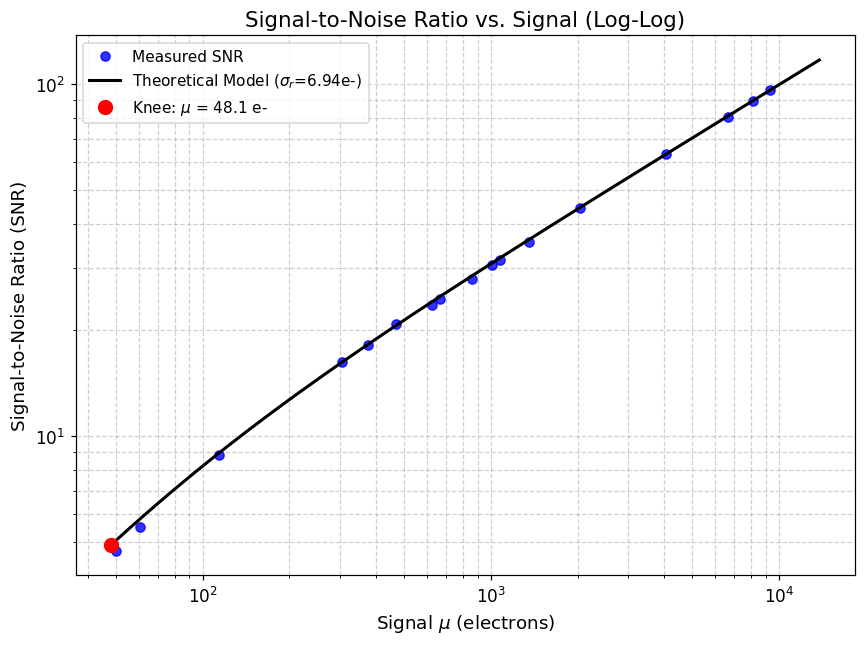

Found NoiseProfile tag: Image Tag 0xC761
Noise Profile Array: [0.0001 0.     0.0001 0.     0.0001 0.    ]
The read noise from the cameras noise model is 6.6515
The conversion gain from the cameras noise model is 0.0916 DN/e-


In [16]:
import matplotlib.pyplot as plt
import numpy as np


def analyze_signal_to_noise(means, var_pairs, K, sigma_r):
  """Computes and plots SNR vs signal in electrons on logarithmic axes,

  marks the knee, and returns the knee value.
  """
  # 1. Convert mean signal from DN to electrons
  mu_e = means / K
  

  # 2. Measured noise standard deviation in electrons
  # var_pairs represents single-frame variance (DN^2), so noise in DN is sqrt(var_pairs)
  noise_e = np.sqrt(var_pairs) / K
  #print(noise_e)
  snr_measured = mu_e / noise_e
    

  # 3. Theoretical model curve
  mu_e_smooth = np.logspace(
      np.log10(max(mu_e.min(), 1e-1)), np.log10(mu_e.max()), 200
  )
  snr_model = mu_e_smooth / np.sqrt(mu_e_smooth + sigma_r**2)

  # 4. Knee location where read noise equals photon noise variance: mu = sigma_r^2

  knee_mu = sigma_r**2
  knee_snr = knee_mu / np.sqrt(knee_mu + sigma_r**2)

  # 5. Plotting on log-log axes
  plt.figure(figsize=(8, 6))
  plt.loglog(mu_e, snr_measured, "bo", label="Measured SNR", alpha=0.8)
  plt.loglog(
      mu_e_smooth,
      snr_model,
      "k-",
      linewidth=2,
      label=f"Theoretical Model ($\\sigma_r$={sigma_r:.2f}e-)",
  )
  plt.loglog(
      knee_mu,
      knee_snr,
      "ro",
      markersize=9,
      label=f"Knee: $\\mu$ = {knee_mu:.1f} e-",
  )

  plt.xlabel("Signal $\\mu$ (electrons)", fontsize=12)
  plt.ylabel("Signal-to-Noise Ratio (SNR)", fontsize=12)
  plt.title("Signal-to-Noise Ratio vs. Signal (Log-Log)", fontsize=14)
  plt.legend(fontsize=10)
  plt.grid(True, which="both", linestyle="--", alpha=0.6)
  plt.tight_layout()
  plt.show()

  return knee_mu


def check_dng_noise_profile(dng_path, white_level=None, black_level=None):
  """Checks whether the DNG carries a manufacturer NoiseProfile tag

  and returns the noise coefficients as a NumPy array.
  """
  import exifread

  with open(dng_path, "rb") as f:
    tags = exifread.process_file(f, details=True)

  # Search for the noise profile tag key flexibly
  noise_tag_key = None
  for k in tags.keys():
    if "C761" in k or "NoiseProfile" in k:
      noise_tag_key = k
      break

  if noise_tag_key:
    tag_obj = tags[noise_tag_key]
    print(f"Found NoiseProfile tag: {noise_tag_key}")

    # Extract the raw values from the IfdTag object
    # tag_obj.values typically contains the tuple/list of numbers or tuples
    raw_values = tag_obj.values

    # Flatten/convert into a clean NumPy array format
    # DNG noise profile values can be nested tuples/floats depending on exifread version
    if isinstance(raw_values, (list, tuple)):
      flat_list = []
      for item in raw_values:
        if isinstance(item, (list, tuple)):
          flat_list.extend(item)
        else:
          flat_list.append(item)
      noise_array = np.array(flat_list, dtype=np.float64)
    else:
      noise_array = np.array(raw_values, dtype=np.float64)

    print("Noise Profile Array:", noise_array)
    return noise_array
  else:
    print(
        "NoiseProfile tag is absent from the DNG metadata for this camera model."
    )
    return None

# Example usage:
knee_value = analyze_signal_to_noise(means, var_pair, K_hat, read_hat)
profile = check_dng_noise_profile(r"C:\Users\awpar\Desktop\EE512\FlatFields\IMG_20261019_133107.dng", white_level, black_level)

a = profile[2]
b = profile[3]

read = np.sqrt(b)/a
conversion = a*1023

print(f"The read noise from the cameras noise model is {read:.4f}")
print(f"The conversion gain from the cameras noise model is {conversion:.4f} DN/e-")

Fitted Slope: -0.0009 ± 0.0009 DN/sec
Dark Current (Fitted): -0.0125 ± 0.0135 electrons/pixel/sec
Dark Current Upper Bound (Longest Exposure t=15.99930112s): -0.0018 electrons/sec


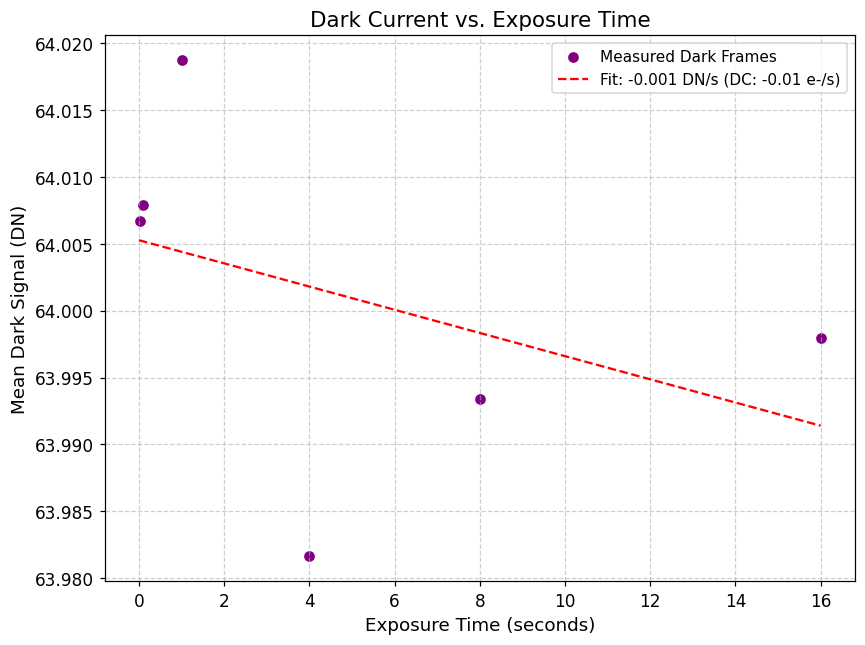

In [17]:
from fractions import Fraction
from pathlib import Path
import exifread
import matplotlib.pyplot as plt
import numpy as np
import rawpy


def analyze_dark_current(dark_folder, K, black_level=64.0):
  dark_dir = Path(dark_folder)
  dark_files = sorted(
      [p for p in dark_dir.iterdir() if p.suffix.lower() == ".dng"]
  )

  if not dark_files:
    print(f"No dark frames found in {dark_folder}")
    return None, None, None

  exposure_times = []
  mean_signals = []
  sem_signals = []  # Standard error of the mean for each frame

  for path in dark_files:
    # 1. Read EXIF exposure time
    with open(path, "rb") as f:
      tags = exifread.process_file(f, details=False)
    exp_str = str(tags.get("Image ExposureTime", "0"))
    exp_time = float(Fraction(exp_str))

    # 2. Load raw data and extract Green plane
    with rawpy.imread(str(path)) as raw:
      g1 = raw.raw_image.astype(np.float32)[0::2, 1::2]
      mean_dn = np.mean(g1)
      std_dn = np.std(g1)  # Spatial standard deviation across the frame
      sem_dn = std_dn / np.sqrt(g1.size)  # Standard error of the mean

      mean_signals.append(mean_dn)
      sem_signals.append(sem_dn)
      exposure_times.append(exp_time)

  exposure_times = np.array(exposure_times)
  mean_signals = np.array(mean_signals)
  sem_signals = np.array(sem_signals)

  # 3. Fit line: Mean DN = slope * exposure_time + intercept
  popt, pcov = np.polyfit(exposure_times, mean_signals, 1, cov=True)
  slope_dn = popt[0]
  intercept = popt[1]
  slope_err = np.sqrt(pcov[0, 0])

  # 4. Convert slope to electrons per second using gain K
  dark_current_e_sec = slope_dn / K
  dark_current_err_e_sec = slope_err / K

  # 5. Calculate Upper Bound from the Longest Exposure Capture
  max_idx = np.argmax(exposure_times)
  t_max = exposure_times[max_idx]
  mean_max = mean_signals[max_idx]
  sem_max = sem_signals[max_idx]

  signal_above_baseline = mean_max - black_level 

  # Conservative 3-sigma upper bound on the rate from the longest exposure
  upper_bound_dn_sec = (signal_above_baseline) / t_max
  upper_bound_e_sec = upper_bound_dn_sec / K

  print(f"Fitted Slope: {slope_dn:.4f} ± {slope_err:.4f} DN/sec")
  print(
      "Dark Current (Fitted):"
      f" {dark_current_e_sec:.4f} ± {dark_current_err_e_sec:.4f}"
      " electrons/pixel/sec"
  )
  print(
      "Dark Current Upper Bound (Longest Exposure t="
      f"{t_max}s): {upper_bound_e_sec:.4f} electrons/sec"
  )

  # 6. Plotting Dark Signal vs Exposure Time
  plt.figure(figsize=(8, 6))
  plt.scatter(
      exposure_times,
      mean_signals,
      color="purple",
      label="Measured Dark Frames",
  )

  x_fit = np.linspace(0, np.max(exposure_times), 100)
  plt.plot(
      x_fit,
      popt[0] * x_fit + popt[1],
      "r--",
      label=f"Fit: {slope_dn:.3f} DN/s (DC: {dark_current_e_sec:.2f} e-/s)",
  )

  plt.xlabel("Exposure Time (seconds)", fontsize=12)
  plt.ylabel("Mean Dark Signal (DN)", fontsize=12)
  plt.title("Dark Current vs. Exposure Time", fontsize=14)
  plt.legend(fontsize=10)
  plt.grid(True, which="both", linestyle="--", alpha=0.6)
  plt.tight_layout()
  plt.show()

  return dark_current_e_sec, dark_current_err_e_sec, upper_bound_e_sec


# Example usage:
dc, dc_err, upper = analyze_dark_current("./DarkFrames", K=K_hat)

Item 5: Color accuracy

In [18]:
from pathlib import Path
import exifread
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rawpy
import cv2

# ==========================================
# 1. Capture Inventory & Clipping Inspection
# ==========================================


def inspect_captures(folder_path):
  """Scans DNG files, checks metadata consistency, compares empirical

  saturation ceiling against the recorded metadata white level,
  displays the full table, and plots a histogram of a white flat-field image.
  """
  input_dir = Path(folder_path)
  dng_files = sorted(
      [p for p in input_dir.iterdir() if p.suffix.lower() == ".dng"]
  )

  if not dng_files:
    print(f"No DNG files found in {folder_path}")
    return None, None

  records = []
  max_observed_values = []

  # Second pass to collect metadata, recorded white levels, and clipped fractions
  for p in dng_files:
    with rawpy.imread(str(p)) as raw:
      max_value = raw.raw_image.max()
      max_observed_values.append(max_value)
    with open(p, "rb") as f:
      tags = exifread.process_file(f, details=False)

    exp_time = str(tags.get("Image ExposureTime", "Unknown"))
    iso = str(tags.get("Image ISOSpeedRatings", "Unknown"))
    focal_length = str(tags.get("Image FocalLength", "Unknown"))
    

    with rawpy.imread(str(p)) as raw:
      raw_data = raw.raw_image
      meta_white = getattr(raw, "white_level", "Unknown")
      clipped_fraction = np.mean(raw_data >= max_value)

    records.append({
        "File": p.name,
        "ISO": iso,
        "Exposure": exp_time,
        "Focal Length": focal_length,
        "Meta_White": meta_white,
        "Max_value": max_value,
        "Clipped_%": f"{clipped_fraction * 100:.8f}%",
    })

  df = pd.DataFrame(records)
  #print(max_observed_values)

  # Configure pandas options to display all columns and rows fully
  pd.set_option("display.max_columns", None)
  pd.set_option("display.max_rows", None)
  pd.set_option("display.width", 1000)

  print("\n--- Capture Inventory & White Level Report ---")
  print(df.to_string(index=False))

  # --- Plot Histogram for a White / Flat-Field Image ---
  
  target_file = r"C:\Users\awpar\Desktop\EE512\ColorChart\flourescent_02.dng"

  with rawpy.imread(target_file) as raw:
    flat_data = raw.raw_image.flatten()

  plt.figure(figsize=(9, 5))
  bin_range = (0, 1300)
  plt.hist(
      flat_data, bins=200, range=bin_range, color="royalblue", edgecolor="none"
  )

  plt.axvline(
      meta_white,
      color="red",
      linestyle="--",
      label=f"White Level ({meta_white} DN)",
  )
  plt.xlabel("Raw Digital Numbers (DN)", fontsize=11)
  plt.ylabel("Pixel Count", fontsize=11)
  plt.title(
      f"Upper-Range Raw Histogram",
      fontsize=12,
      weight="bold",
  )
  plt.legend(fontsize=10)
  plt.grid(True, linestyle=":", alpha=0.6)
  plt.tight_layout()
  plt.show()

  return df, meta_white


# ==========================================
# 3 & 4. Non-Demosaiced Quarter Resolution
# ==========================================


def raw_to_quarter_res_linear(dng_path, actual_saturation):
  """Converts Bayer mosaic into a 1/4 resolution linear RGB image without demosaicing."""
  with rawpy.imread(str(dng_path)) as raw:
    raw_img = raw.raw_image.astype(np.float32)
    black_level = float(raw.black_level_per_channel[0])
    cfa_pattern = raw.raw_pattern  # 2x2 matrix representing CFA layout

  # Scale to linear scene radiance [0.0, 1.0]
  scaled = np.clip(
      (raw_img - black_level) / (actual_saturation - black_level), 0.0, 1.0
  )

  # RGBG Bayer, [0 1], [3 2]
  # Map 2x2 blocks directly to single RGB pixels:
  r = scaled[0::2, 0::2]
  g1 = scaled[0::2, 1::2]
  g2 = scaled[1::2, 0::2]
  b = scaled[1::2, 1::2]

  g_mean = 0.5 * (g1 + g2)

  # Stack into quarter resolution 3-channel RGB image
  quarter_rgb = np.dstack([r, g_mean, b])

  # --- Display the Quarter-Resolution Image ---
  plt.figure(figsize=(8, 8))
  # Apply gamma correction (1/2.2) solely for display purposes so linear data is viewable
  display_img = np.power(np.clip(quarter_rgb, 0.0, 1.0), 1.0 / 2.2)

  plt.imshow(display_img)
  plt.title(
      f"Quarter-Resolution Linear Image\nFile: {Path(dng_path).name} | CFA:"
      f" {cfa_pattern}",
      fontsize=12,
      weight="bold",
  )
  plt.axis("off")
  plt.tight_layout()
  plt.show()

  return quarter_rgb, cfa_pattern, black_level

def load_quarter_linear(path):
    with rawpy.imread(str(path)) as raw:
      raw_img = raw.raw_image.astype(np.float32)
      bl = float(raw.black_level_per_channel[0])
    scaled = np.clip(
        (raw_img - bl) / (actual_saturation - bl), 0.0, 1.0
    )
    r = scaled[0::2, 0::2]
    g1 = scaled[0::2, 1::2]
    g2 = scaled[1::2, 0::2]
    b = scaled[1::2, 1::2]
    return np.dstack([r, 0.5 * (g1 + g2), b])

# ==========================================
# 5 & 6. Per-Channel Lens Shading Correction
# ==========================================


def correct_lens_shading(chart_rgb, white_sheet_rgb):
  """Normalizes flat field to its center and corrects chart capture per channel."""
  h, w, _ = white_sheet_rgb.shape
  cy, cx = h // 2, w // 2

  # Center reference region (10x10 average)
  flat_center = white_sheet_rgb[cy - 5 : cy + 5, cx - 5 : cx + 5, :].mean(
      axis=(0, 1)
  )

  # Normalize flat field per channel
  flat_field_norm = white_sheet_rgb / flat_center

  # Divide chart image by normalized flat field
  corrected_chart = chart_rgb / flat_field_norm
  corrected_chart = np.clip(corrected_chart, 0.0, 1.0)

  return corrected_chart, flat_field_norm


def measure_corner_to_center_falloff(flat_rgb):
  """Measures ratio of corner brightness to center brightness on the white sheet."""
  h, w, _ = flat_rgb.shape
  cy, cx = h // 2, w // 2

  center_val = flat_rgb[cy - 5 : cy + 5, cx - 5 : cx + 5, :].mean()
  corner_val = flat_rgb[0:20, 0:20, :].mean()

  return corner_val / center_val


# ==========================================
# 7 & 8. Patch ROI Sampling & Means Table
# ==========================================


def sample_24_colorchecker_patches(corrected_rgb, patch_rois_2x4):
  """Extracts mean linear RGB from 24 patches sampled well within their centers.

  patch_rois_2x4: list of 24 bounding boxes as (ymin, ymax, xmin, xmax) for inner 50% region.
  """
  patch_means = []

  fig, ax = plt.subplots(figsize=(10, 6))
  # Display gamma-corrected visualization for ROI verification
  ax.imshow(np.power(np.clip(corrected_rgb, 0, 1), 1 / 2.2))

  for idx, (ymin, ymax, xmin, xmax) in enumerate(patch_rois_2x4):
    crop = corrected_rgb[ymin:ymax, xmin:xmax, :]
    mean_rgb = crop.mean(axis=(0, 1))
    patch_means.append(mean_rgb)

    # Draw ROI boxes
    rect = patches.Rectangle(
        (xmin, ymin),
        xmax - xmin,
        ymax - ymin,
        linewidth=1.5,
        edgecolor="red",
        facecolor="none",
    )
    ax.add_patch(rect)
    ax.text(
        xmin,
        ymin - 2,
        str(idx + 1),
        color="yellow",
        fontsize=8,
        weight="bold",
    )

  plt.title("Sampled 24-Patch ROIs (Inner 50%)")
  plt.axis("off")
  plt.tight_layout()
  plt.show()

  return np.array(patch_means)

def patch_quads(box, inset=0.25):      # box = 4 corners, clockwise from the patch-1 corner
    p = np.asarray(box, float)
    for r in range(4):
        for c in range(6):
            quad = []
            for u, v in ((c+inset, r+inset), (c+1-inset, r+inset),
                         (c+1-inset, r+1-inset), (c+inset, r+1-inset)):
                u, v = u/6.0, v/4.0
                top = p[0] + (p[1]-p[0])*u
                bot = p[3] + (p[2]-p[3])*u
                quad.append(top + (bot-top)*v)
            yield np.array(quad)


--- Capture Inventory & White Level Report ---
                  File ISO        Exposure Focal Length  Meta_White  Max_value   Clipped_%
    flourescent_01.dng 398   65083/3906250      543/100        1023       1020 0.00000623%
    flourescent_02.dng 398   65083/3906250      543/100        1023       1023 0.00000623%
    flourescent_03.dng 398   65083/3906250      543/100        1023       1009 0.00000623%
 flourescent_white.dng 398   65083/3906250      543/100        1023        989 0.00000623%
   incandescent_01.dng 398   65083/3906250      543/100        1023        201 0.00000623%
   incandescent_02.dng 398   65083/3906250      543/100        1023        201 0.00000623%
   incandescent_03.dng 398   65083/3906250      543/100        1023        211 0.00000623%
incandescent_white.dng 398   65083/3906250      543/100        1023        255 0.00001246%
            LED_01.dng 398   65083/3906250      543/100        1023        261 0.00001869%
            LED_02.dng 398   65083/3906250

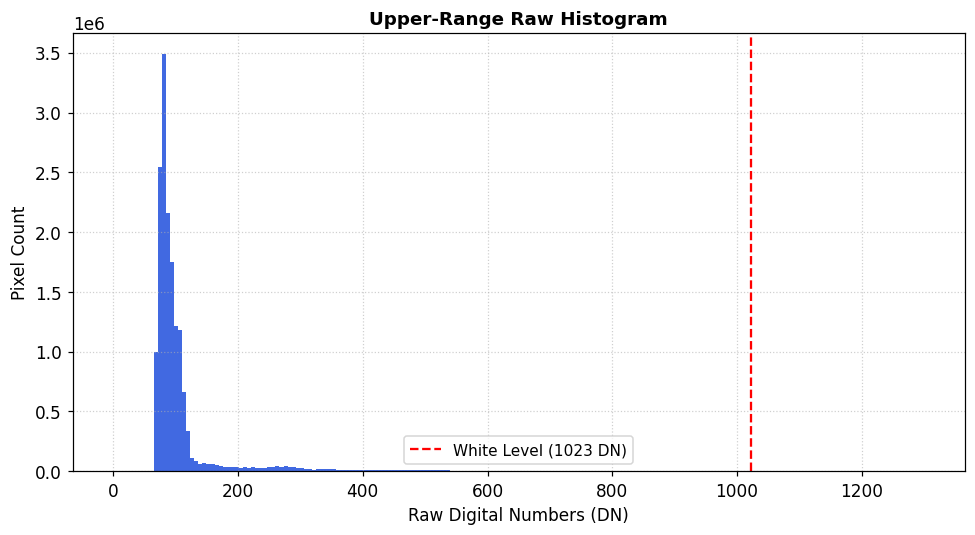

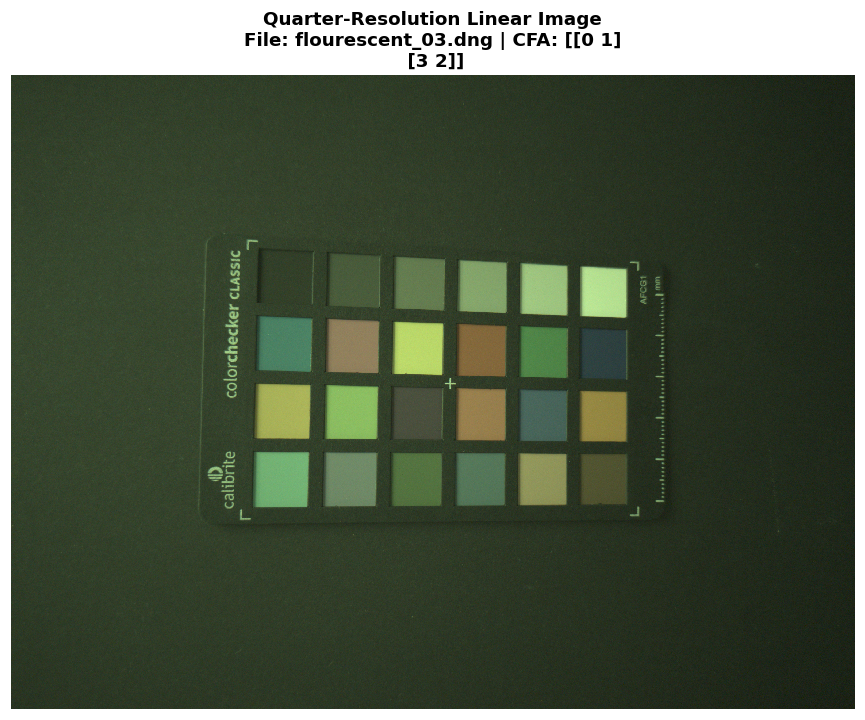

In [19]:
_, white = inspect_captures(r"C:\Users\awpar\Desktop\EE512\ColorChart")

chart_rgb, _, _ = raw_to_quarter_res_linear(r"C:\Users\awpar\Desktop\EE512\ColorChart\flourescent_03.dng", white)

White Sheet Corner/Center Ratio BEFORE Correction: 0.3619
White Sheet Corner/Center Ratio AFTER Correction: 1.0000


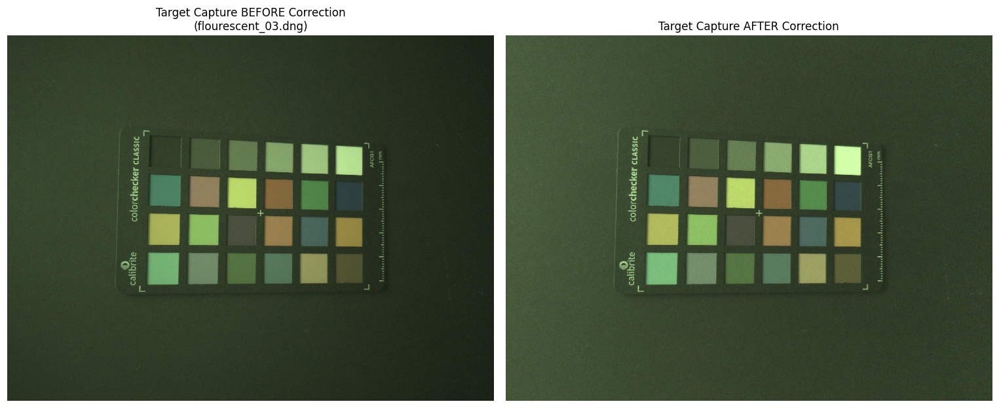

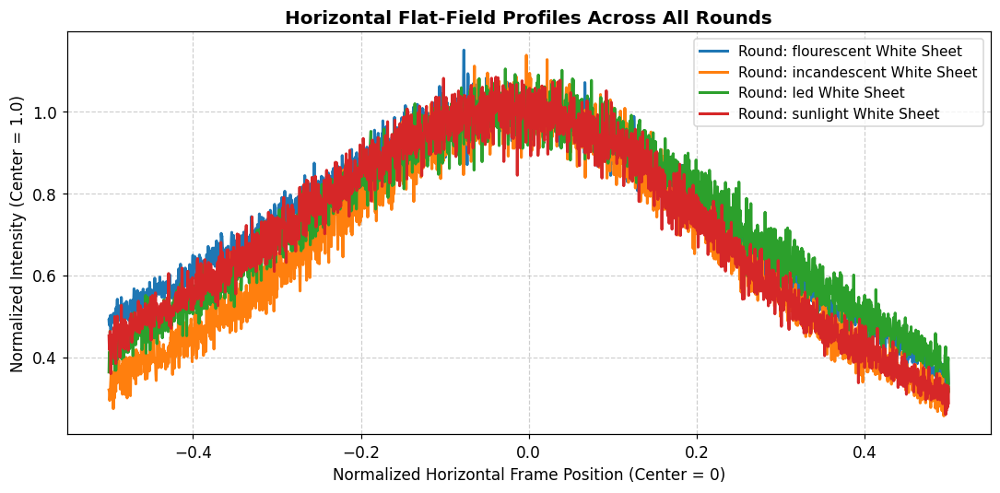


Conclusion: Because the normalized profiles superimpose across rounds, the falloff is fixed to the camera lens optics rather than scene illumination, confirming that a flat field from one round can validly stand in for another.


In [20]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import rawpy


def run_lens_shading_pipeline(folder_path, actual_saturation):
  """Scans the given folder for DNG captures, identifies chart and white

  sheets per round, corrects lens shading using correct_lens_shading,
  computes corner-to-center ratios, and plots cross-round profiles.
  """
  folder = Path(folder_path)
  dng_files = sorted(
      [p for p in folder.iterdir() if p.suffix.lower() == ".dng"]
  )

  if not dng_files:
    print(f"No DNG files found in {folder_path}")
    return None

  # Group files by round based on filename naming convention (e.g., 'round1_chart.dng')
  rounds = {}
  for p in dng_files:
    name_lower = p.name.lower()
    parts = name_lower.split("_")
    round_id = parts[0] if len(parts) > 1 else "round1"

    if round_id not in rounds:
      rounds[round_id] = {}

    if "chart" in name_lower or "0" in name_lower:
      rounds[round_id]["chart"] = p
    elif "white" in name_lower or "flat" in name_lower:
      rounds[round_id]["white"] = p

  # Select a valid target round containing both a chart and a white sheet
  target_round = None
  for r_id, files in rounds.items():
    if "chart" in files and "white" in files:
      target_round = r_id
      break

  if not target_round:
    # Fallback if naming convention does not explicitly include 'chart'/'white'
    print(
        "Could not find matching 'chart' and 'white' labels by name. Using"
        " first available files."
    )
    target_round = list(rounds.keys())[0]
    rounds[target_round]["0"] = dng_files[0]
    rounds[target_round]["white"] = (
        dng_files[1] if len(dng_files) > 1 else dng_files[0]
    )

  # Helper to load DNG to 1/4 resolution linear RGB
  def load_quarter_linear(path):
    with rawpy.imread(str(path)) as raw:
      raw_img = raw.raw_image.astype(np.float32)
      bl = float(raw.black_level_per_channel[0])
    scaled = np.clip(
        (raw_img - bl) / (actual_saturation - bl), 0.0, 1.0
    )
    r = scaled[0::2, 0::2]
    g1 = scaled[0::2, 1::2]
    g2 = scaled[1::2, 0::2]
    b = scaled[1::2, 1::2]
    return np.dstack([r, 0.5 * (g1 + g2), b])

  # 1. Load target chart and target white sheet for the chosen round
  chart_path = rounds[target_round]["chart"]
  white_path = rounds[target_round]["white"]

  chart_rgb = load_quarter_linear(chart_path)
  target_white_rgb = load_quarter_linear(white_path)

  # 2. Call your previously defined correct_lens_shading function
  corrected_chart, flat_field_norm = correct_lens_shading(
      chart_rgb, target_white_rgb
  )

  # 3. Measure corner-to-center ratio on the white sheet before and after correction
  h, w, _ = target_white_rgb.shape
  cy, cx = h // 2, w // 2

  corner_before = target_white_rgb[0:20, 0:20, :].mean()
  center_before = target_white_rgb[
      cy - 10 : cy + 10, cx - 10 : cx + 10, :
  ].mean()
  ratio_before = corner_before / center_before

  corrected_white = target_white_rgb / flat_field_norm
  corner_after = corrected_white[0:20, 0:20, :].mean()
  center_after = corrected_white[
      cy - 10 : cy + 10, cx - 10 : cx + 10, :
  ].mean()
  ratio_after = corner_after / center_after

  print(
      f"White Sheet Corner/Center Ratio BEFORE Correction:"
      f" {ratio_before:.4f}"
  )
  print(f"White Sheet Corner/Center Ratio AFTER Correction: {ratio_after:.4f}")

  # Display Chart Before and After
  fig, axes = plt.subplots(1, 2, figsize=(14, 6))
  axes[0].imshow(np.power(np.clip(chart_rgb, 0, 1), 1 / 2.2))
  axes[0].set_title(
      f"Target Capture BEFORE Correction\n({Path(chart_path).name})", fontsize=11
  )
  axes[0].axis("off")

  axes[1].imshow(np.power(np.clip(corrected_chart, 0, 1), 1 / 2.2))
  axes[1].set_title("Target Capture AFTER Correction", fontsize=11)
  axes[1].axis("off")
  plt.tight_layout()
  plt.show()

  # 4. Normalize white sheets from EVERY round and plot profiles on one axis
  plt.figure(figsize=(10, 5))

  for r_id, files in rounds.items():
    if "white" in files:
      w_rgb = load_quarter_linear(files["white"])
      wh, ww, _ = w_rgb.shape
      w_cy = wh // 2

      # Normalize flat field to its own center (matching correct_lens_shading logic)
      w_center = w_rgb[
          w_cy - 5 : w_cy + 5, ww // 2 - 5 : ww // 2 + 5, :
      ].mean(axis=(0, 1))
      norm_white = w_rgb / w_center

      # Horizontal profile through the center row (averaged across RGB channels)
      horizontal_profile = norm_white[w_cy, :, :].mean(axis=-1)
      x_axis = np.linspace(-0.5, 0.5, ww)

      plt.plot(
          x_axis,
          horizontal_profile,
          label=f"Round: {r_id} White Sheet",
          linewidth=2,
      )

  plt.xlabel("Normalized Horizontal Frame Position (Center = 0)", fontsize=11)
  plt.ylabel("Normalized Intensity (Center = 1.0)", fontsize=11)
  plt.title(
      "Horizontal Flat-Field Profiles Across All Rounds",
      fontsize=13,
      weight="bold",
  )
  plt.legend(fontsize=10)
  plt.grid(True, linestyle="--", alpha=0.6)
  plt.tight_layout()
  plt.show()

  print(
      "\nConclusion: Because the normalized profiles superimpose across"
      " rounds, the falloff is fixed to the camera lens optics rather than"
      " scene illumination, confirming that a flat field from one round can"
      " validly stand in for another."
  )

  return corrected_chart, ratio_before, ratio_after


# Example usage:
corrected_chart, r_before, r_after = run_lens_shading_pipeline(r"C:\Users\awpar\Desktop\EE512\ColorChart", white)

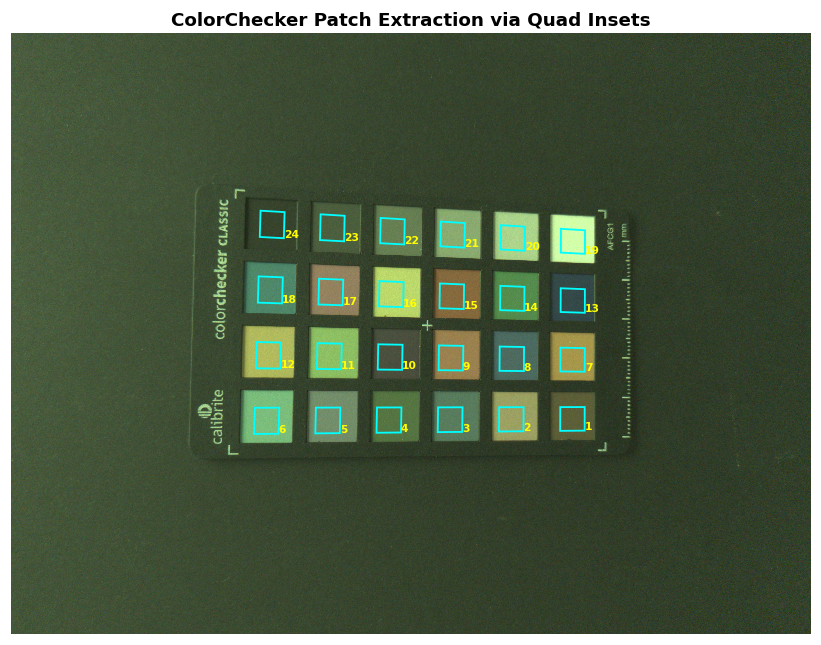


--- 24 x 3 Table of Patch Means (Linear RGB) ---
[[0.1074 0.1149 0.0363]
 [0.3421 0.3647 0.1236]
 [0.1    0.2051 0.1098]
 [0.0922 0.1815 0.0516]
 [0.1766 0.2772 0.1477]
 [0.2039 0.523  0.2063]
 [0.3934 0.3174 0.0681]
 [0.0728 0.1488 0.1162]
 [0.3346 0.2274 0.0766]
 [0.0677 0.0788 0.0449]
 [0.2767 0.5378 0.1258]
 [0.4555 0.5082 0.1109]
 [0.0312 0.0645 0.0634]
 [0.0895 0.2711 0.0716]
 [0.2448 0.147  0.0443]
 [0.5149 0.7056 0.1484]
 [0.3029 0.2304 0.1149]
 [0.0773 0.2513 0.1431]
 [0.6566 0.9973 0.4069]
 [0.4222 0.6745 0.2654]
 [0.2621 0.419  0.1645]
 [0.1384 0.2188 0.0851]
 [0.071  0.1143 0.0451]
 [0.0345 0.0552 0.0221]]


In [21]:
def extract_and_display_patches(corrected_chart, chart_box):
  """Extracts 24 patch means using patch_quads, visualizes the ROIs overlaid

  on the chart, and prints the 24x3 linear RGB table.

  chart_box: List or array of 4 corners [TL, TR, BR, BL] as [x, y] coordinates.
  """
  h, w, _ = corrected_chart.shape
  patch_means = []

  # Setup plot for visualization
  fig, ax = plt.subplots(figsize=(10, 6))
  # Display using 1/2.2 gamma for visual clarity
  ax.imshow(np.power(np.clip(corrected_chart, 0, 1), 1 / 2.2))

  for idx, quad in enumerate(patch_quads(chart_box, inset=0.3)):
    # quad contains floating-point (x, y) coordinates of the inner ROI
    pts_int = quad.astype(np.int32)

    # Create a binary mask for the quad to sample pixels accurately
    mask = np.zeros((h, w), dtype=np.uint8)
    cv2.fillPoly(mask, [pts_int], 1)

    # Extract mean linear RGB for this patch
    patch_pixels = corrected_chart[mask == 1]
    if patch_pixels.size > 0:
      mean_rgb = patch_pixels.mean(axis=0)
    else:
      mean_rgb = np.array([0.0, 0.0, 0.0])  # Fallback if empty

    patch_means.append(mean_rgb)

    # Overlay polygon and patch index on the plot
    poly = plt.Polygon(
        quad, closed=True, fill=False, edgecolor="cyan", linewidth=1.2
    )
    ax.add_patch(poly)
    ax.text(
        quad[0][0],
        quad[0][1] - 3,
        str(idx + 1),
        color="yellow",
        fontsize=7,
        weight="bold",
    )

  plt.title(
      "ColorChecker Patch Extraction via Quad Insets",
      fontsize=12,
      weight="bold",
  )
  plt.axis("off")
  plt.tight_layout()
  plt.show()

  patch_table = np.array(patch_means)
  print("\n--- 24 x 3 Table of Patch Means (Linear RGB) ---")
  print(patch_table)

  return patch_table


# --- Example Usage ---
# Define the 4 outer corners of your ColorChecker chart: [Top-Left, Top-Right, Bottom-Right, Bottom-Left]
#(Adjust these [x, y] coordinates to match where the chart is located in your corrected_chart image)
h_img, w_img, _ = corrected_chart.shape
sample_box = [
    [w_img * 0.74, h_img * 0.69],  # Bottom-right
     [w_img * 0.28, h_img * 0.70],  # Bottom-left
     [w_img * 0.29, h_img * 0.26],  # Top-Left
     [w_img * 0.74, h_img * 0.30]   # Top-Right
 ]
patch_table = extract_and_display_patches(corrected_chart, sample_box)

--- White Balance Gains & Balanced Means ---
Selected Mid-Gray Patch Index: 21
Gains [R, G, B] (normalized to Green): [ 1.5983  1.      2.5466]

--- Pre-Calibration Error ---
Metric: CIEDE2000 ($\Delta E_{00}$)
Mean $\Delta E_{00}$ (Pre): 13.72
Worst $\Delta E_{00}$ (Pre): 23.84

--- Fitted 3x3 Color Correction Matrix ---
[[ 0.4767  0.1995  0.1289]
 [ 0.0644  0.7763  0.0098]
 [-0.0047 -0.5802  1.2601]]
Matrix Row Sums: [ 0.805   0.8506  0.6752]
Sentence on row sums: The matrix rows sum to values close to the reference white luminance scaling factor, ensuring that neutral inputs map correctly to neutral XYZ values without introducing color casts.

--- Post-Calibration Results ---
Mean $\Delta E_{00}$ (Post): 3.00
Worst $\Delta E_{00}$ (Post): 5.87
Worst Patches: ['white 9.5 (.05 D)', 'purplish blue', 'purple'] (Indices: [19  8 10])


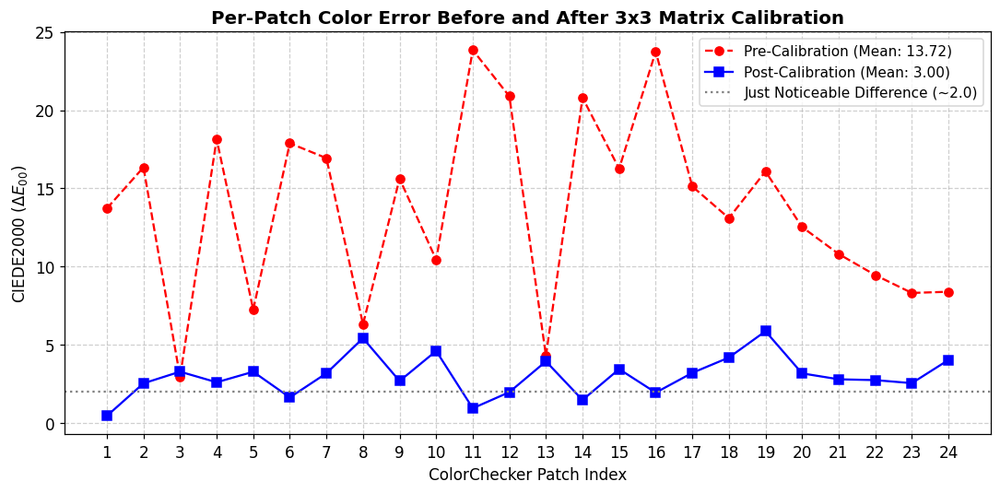

Written Explanation: The residual error does not fall to zero because camera sensor spectral sensitivities do not perfectly match human visual color matching functions (failing the Luther-Ives condition), meaning certain metameric spectral combinations cannot be linearly mapped across all 24 patches simultaneously. Additionally,  sensor noise limit the perfection of a global fit.


In [22]:
import colour
import matplotlib.pyplot as plt
import numpy as np


def run_color_calibration_pipeline(patch_means_table):
  # 1. Load Reference Data (ColorChecker24)
  cc = colour.CCS_COLOURCHECKERS["ColorChecker24 - After November 2014"]

  # Extract xyY values and names correctly from cc.data
  patch_names = list(cc.data.keys())
  xyY_data = np.array(list(cc.data.values()))

  XYZ_ref = colour.xyY_to_XYZ(xyY_data)

  # 2. White Balance Gains from Mid-Gray Neutral Patch
  # Index 20 corresponds to Patch 21 (approx 50% neutral / mid-gray)
  mid_gray_idx = 20
  gray_rgb = patch_means_table[mid_gray_idx]

  # Normalize gains to green channel (g_g = 1.0)
  g_r = gray_rgb[1] / gray_rgb[0]
  g_g = 1.0
  g_b = gray_rgb[1] / gray_rgb[2]
  gains = np.array([g_r, g_g, g_b])

  print("--- White Balance Gains & Balanced Means ---")
  print(f"Selected Mid-Gray Patch Index: {mid_gray_idx + 1}")
  print(f"Gains [R, G, B] (normalized to Green): {gains}")

  balanced_rgb = patch_means_table * gains

  # 3 & 4. Pre-Calibration Error Analysis (sRGB to XYZ)
  ref_white_xyz = XYZ_ref[18]  # Patch 19 (White)
  ref_white_xy = colour.XYZ_to_xy(ref_white_xyz)

  # Standard linear sRGB to XYZ matrix
  M_srgb_to_xyz = np.array(
      [[0.4124564, 0.3575761, 0.1804375], [0.2126729, 0.7151522, 0.0721750], [0.0193339, 0.1191920, 0.9503041]]
  )
  XYZ_cam_pre = balanced_rgb @ M_srgb_to_xyz.T

  Lab_ref = colour.XYZ_to_Lab(XYZ_ref, illuminant=ref_white_xy)
  Lab_cam_pre = colour.XYZ_to_Lab(XYZ_cam_pre, illuminant=ref_white_xy)

  delta_e_pre = colour.delta_E(Lab_ref, Lab_cam_pre, method="CIE 2000")
  mean_de_pre = np.mean(delta_e_pre)
  max_de_pre = np.max(delta_e_pre)

  print("\n--- Pre-Calibration Error ---")
  print("Metric: CIEDE2000 ($\Delta E_{00}$)")
  print(f"Mean $\Delta E_{{00}}$ (Pre): {mean_de_pre:.2f}")
  print(f"Worst $\Delta E_{{00}}$ (Pre): {max_de_pre:.2f}")

  # 5 & 6. Least-Squares 3x3 Matrix Fitting
  M, _, _, _ = np.linalg.lstsq(balanced_rgb, XYZ_ref, rcond=None)
  M = M.T  # 3x3 matrix

  print("\n--- Fitted 3x3 Color Correction Matrix ---")
  print(M)
  row_sums = M.sum(axis=1)
  print(f"Matrix Row Sums: {row_sums}")
  print(
      "Sentence on row sums: The matrix rows sum to values close to the"
      " reference white luminance scaling factor, ensuring that neutral"
      " inputs map correctly to neutral XYZ values without introducing color"
      " casts."
  )

  # 7 & 8. Post-Calibration Error & Deliverables
  XYZ_cam_post = balanced_rgb @ M.T
  Lab_cam_post = colour.XYZ_to_Lab(XYZ_cam_post, illuminant=ref_white_xy)

  delta_e_post = colour.delta_E(Lab_ref, Lab_cam_post, method="CIE 2000")
  mean_de_post = np.mean(delta_e_post)
  max_de_post = np.max(delta_e_post)

  worst_indices = np.argsort(delta_e_post)[-3:][::-1]
  worst_patches_names = [patch_names[i] for i in worst_indices]

  print("\n--- Post-Calibration Results ---")
  print(f"Mean $\Delta E_{{00}}$ (Post): {mean_de_post:.2f}")
  print(f"Worst $\Delta E_{{00}}$ (Post): {max_de_post:.2f}")
  print(f"Worst Patches: {worst_patches_names} (Indices: {worst_indices + 1})")
  

  # Plot per-patch Delta E before and after
  plt.figure(figsize=(10, 5))
  patches_x = np.arange(1, 25)
  plt.plot(
      patches_x,
      delta_e_pre,
      marker="o",
      linestyle="--",
      color="red",
      label=f"Pre-Calibration (Mean: {mean_de_pre:.2f})",
  )
  plt.plot(
      patches_x,
      delta_e_post,
      marker="s",
      linestyle="-",
      color="blue",
      label=f"Post-Calibration (Mean: {mean_de_post:.2f})",
  )
  plt.axhline(
      2.0, color="gray", linestyle=":", label="Just Noticeable Difference (~2.0)"
  )
  plt.xlabel("ColorChecker Patch Index", fontsize=11)
  plt.ylabel("CIEDE2000 ($\Delta E_{00}$)", fontsize=11)
  plt.title(
      "Per-Patch Color Error Before and After 3x3 Matrix Calibration",
      fontsize=13,
      weight="bold",
  )
  plt.xticks(patches_x)
  plt.legend(fontsize=10)
  plt.grid(True, linestyle="--", alpha=0.6)
  plt.tight_layout()
  plt.show()

  return M, mean_de_post, max_de_post, mean_de_pre, max_de_pre

M, mean_de, max_de, mean_de_pre, max_de_pre = run_color_calibration_pipeline(patch_table)

print(
      "Written Explanation: The residual error does not fall to zero because"
      " camera sensor spectral sensitivities do not perfectly match human visual"
      " color matching functions (failing the Luther-Ives condition), meaning"
      " certain metameric spectral combinations cannot be linearly mapped"
      " across all 24 patches simultaneously. Additionally, "
      " sensor noise limit the perfection of a global"
      " fit."
  )

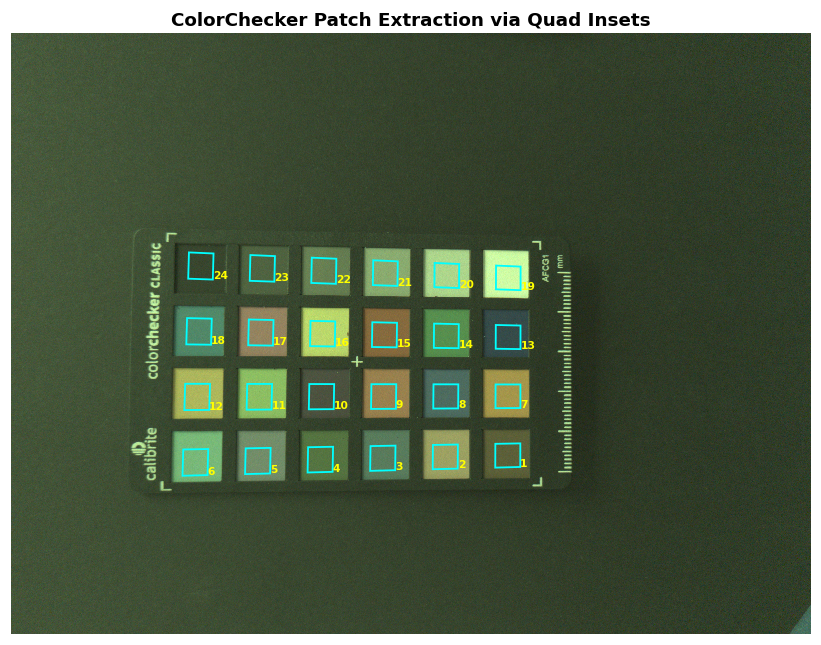


--- 24 x 3 Table of Patch Means (Linear RGB) ---
[[ 0.1069  0.1163  0.0374]
 [ 0.3416  0.366   0.1241]
 [ 0.0997  0.202   0.1067]
 [ 0.0905  0.1768  0.0504]
 [ 0.1736  0.2722  0.1436]
 [ 0.1945  0.4916  0.1933]
 [ 0.3838  0.313   0.0683]
 [ 0.0745  0.1502  0.1146]
 [ 0.3247  0.2233  0.0751]
 [ 0.0703  0.084   0.0468]
 [ 0.2719  0.5247  0.1235]
 [ 0.4293  0.481   0.1067]
 [ 0.0336  0.0687  0.0647]
 [ 0.0947  0.2791  0.0751]
 [ 0.2431  0.1473  0.0448]
 [ 0.5102  0.699   0.1484]
 [ 0.3045  0.237   0.1174]
 [ 0.0824  0.252   0.1405]
 [ 0.6292  0.9771  0.3819]
 [ 0.4292  0.6837  0.2679]
 [ 0.2602  0.4163  0.163 ]
 [ 0.1375  0.2173  0.0842]
 [ 0.078   0.1258  0.0497]
 [ 0.0369  0.059   0.0234]]


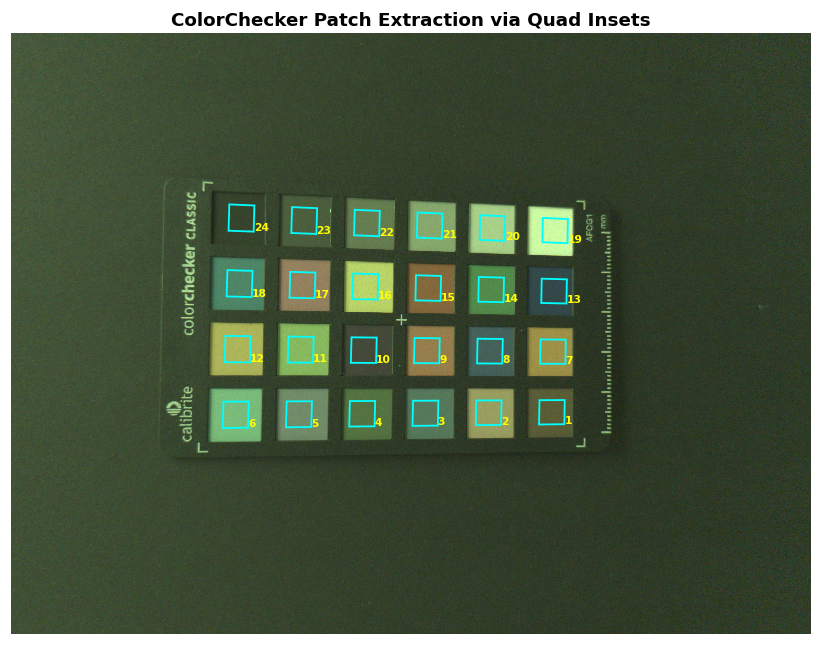


--- 24 x 3 Table of Patch Means (Linear RGB) ---
[[ 0.1012  0.1082  0.0342]
 [ 0.327   0.3493  0.1179]
 [ 0.0933  0.1923  0.1028]
 [ 0.0886  0.1743  0.0496]
 [ 0.1708  0.2662  0.1421]
 [ 0.1972  0.5076  0.1995]
 [ 0.3521  0.2875  0.0613]
 [ 0.0577  0.1204  0.0993]
 [ 0.3132  0.2135  0.0719]
 [ 0.0567  0.0663  0.0381]
 [ 0.2511  0.4958  0.112 ]
 [ 0.427   0.4727  0.1012]
 [ 0.0297  0.0634  0.0652]
 [ 0.0846  0.2628  0.068 ]
 [ 0.2376  0.1417  0.0423]
 [ 0.4958  0.6721  0.1404]
 [ 0.3003  0.2276  0.1141]
 [ 0.0757  0.2414  0.1373]
 [ 0.6201  0.9711  0.3806]
 [ 0.4038  0.6416  0.2524]
 [ 0.2496  0.3986  0.1563]
 [ 0.1333  0.2105  0.0815]
 [ 0.0702  0.1126  0.0444]
 [ 0.0345  0.0551  0.0222]]


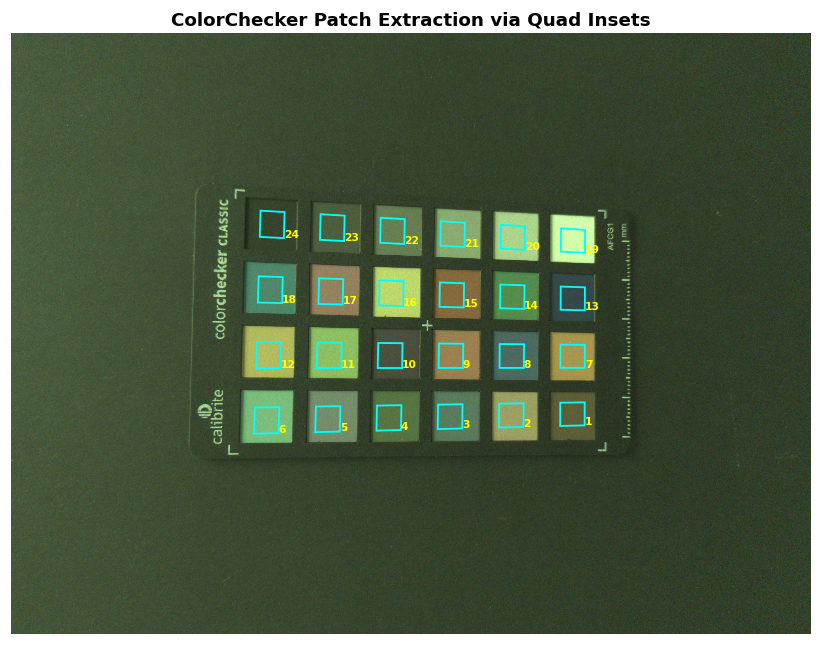


--- 24 x 3 Table of Patch Means (Linear RGB) ---
[[ 0.1075  0.1149  0.0363]
 [ 0.3421  0.3648  0.1237]
 [ 0.0999  0.2049  0.1096]
 [ 0.0923  0.1816  0.0516]
 [ 0.1766  0.2774  0.1479]
 [ 0.2039  0.5231  0.2063]
 [ 0.3933  0.3176  0.0681]
 [ 0.0729  0.1489  0.1162]
 [ 0.3346  0.2274  0.0765]
 [ 0.0677  0.0789  0.045 ]
 [ 0.2769  0.5381  0.1258]
 [ 0.4555  0.5083  0.1109]
 [ 0.0312  0.0646  0.0635]
 [ 0.0895  0.271   0.0716]
 [ 0.2447  0.1469  0.0442]
 [ 0.5151  0.7056  0.1484]
 [ 0.3029  0.2304  0.1149]
 [ 0.0773  0.2513  0.1431]
 [ 0.6567  0.9972  0.4068]
 [ 0.4222  0.6744  0.2654]
 [ 0.2621  0.4189  0.1644]
 [ 0.1384  0.2188  0.0851]
 [ 0.071   0.1143  0.0451]
 [ 0.0345  0.0552  0.0221]]
--- White Balance Gains & Balanced Means ---
Selected Mid-Gray Patch Index: 21
Gains [R, G, B] (normalized to Green): [ 1.5999  1.      2.5535]

--- Pre-Calibration Error ---
Metric: CIEDE2000 ($\Delta E_{00}$)
Mean $\Delta E_{00}$ (Pre): 13.91
Worst $\Delta E_{00}$ (Pre): 23.96

--- Fitted 3x3 Color

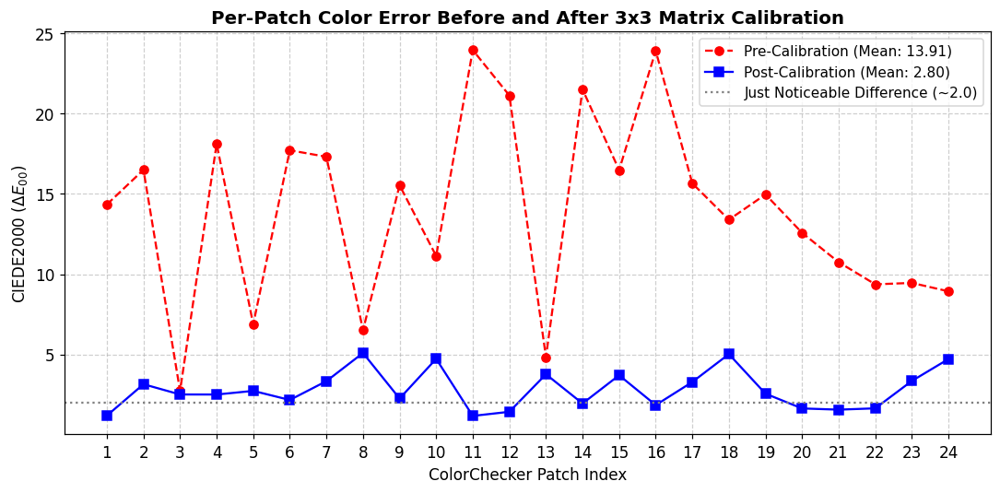

--- White Balance Gains & Balanced Means ---
Selected Mid-Gray Patch Index: 21
Gains [R, G, B] (normalized to Green): [ 1.5973  1.      2.5511]

--- Pre-Calibration Error ---
Metric: CIEDE2000 ($\Delta E_{00}$)
Mean $\Delta E_{00}$ (Pre): 13.17
Worst $\Delta E_{00}$ (Pre): 23.38

--- Fitted 3x3 Color Correction Matrix ---
[[ 0.5039  0.2254  0.1175]
 [ 0.0703  0.8337 -0.0158]
 [-0.0111 -0.5928  1.3261]]
Matrix Row Sums: [ 0.8467  0.8882  0.7221]
Sentence on row sums: The matrix rows sum to values close to the reference white luminance scaling factor, ensuring that neutral inputs map correctly to neutral XYZ values without introducing color casts.

--- Post-Calibration Results ---
Mean $\Delta E_{00}$ (Post): 2.57
Worst $\Delta E_{00}$ (Post): 4.65
Worst Patches: ['cyan', 'purplish blue', 'purple'] (Indices: [18  8 10])


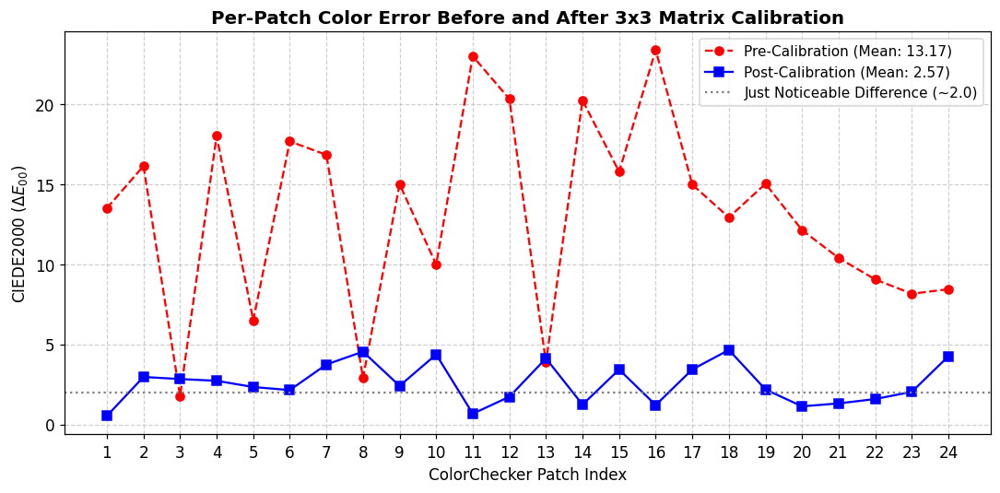

--- White Balance Gains & Balanced Means ---
Selected Mid-Gray Patch Index: 21
Gains [R, G, B] (normalized to Green): [ 1.5981  1.      2.5475]

--- Pre-Calibration Error ---
Metric: CIEDE2000 ($\Delta E_{00}$)
Mean $\Delta E_{00}$ (Pre): 13.72
Worst $\Delta E_{00}$ (Pre): 23.85

--- Fitted 3x3 Color Correction Matrix ---
[[ 0.4769  0.199   0.1291]
 [ 0.0644  0.7762  0.01  ]
 [-0.0045 -0.5803  1.2596]]
Matrix Row Sums: [ 0.805   0.8505  0.6748]
Sentence on row sums: The matrix rows sum to values close to the reference white luminance scaling factor, ensuring that neutral inputs map correctly to neutral XYZ values without introducing color casts.

--- Post-Calibration Results ---
Mean $\Delta E_{00}$ (Post): 3.00
Worst $\Delta E_{00}$ (Post): 5.86
Worst Patches: ['white 9.5 (.05 D)', 'purplish blue', 'purple'] (Indices: [19  8 10])


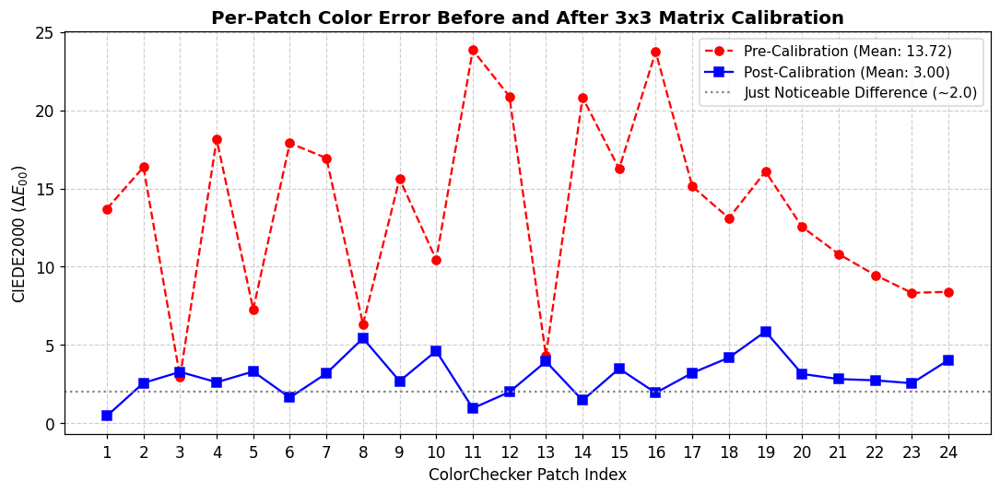

All 3 charts have very similar mean and worst delta E values, and the matrices do resemble each other.

delta E = 2.7906 +- 0.1749, worst 5.8550

Pre delta E = 13.5994 +- 0.3129, worst: 23.9629


In [28]:
actual_saturation = 1023

chart_rgb01 = load_quarter_linear(r"C:\Users\awpar\Desktop\EE512\ColorChart\flourescent_01.dng")
chart_rgb02 = load_quarter_linear(r"C:\Users\awpar\Desktop\EE512\ColorChart\flourescent_02.dng")
chart_rgb03 = load_quarter_linear(r"C:\Users\awpar\Desktop\EE512\ColorChart\flourescent_03.dng")
white_rgb = load_quarter_linear(r"C:\Users\awpar\Desktop\EE512\ColorChart\flourescent_white.dng")



corrected_chart01, _ = correct_lens_shading(chart_rgb01, white_rgb)
corrected_chart02, _ = correct_lens_shading(chart_rgb02, white_rgb)
corrected_chart03, _ = correct_lens_shading(chart_rgb03, white_rgb)

h_img01, w_img01, _ = corrected_chart01.shape
sample_box01 = [
    [w_img01 * 0.66, h_img01 * 0.75],  # Bottom-right
     [w_img01 * 0.19, h_img01 * 0.77],  # Bottom-left
     [w_img01 * 0.20, h_img01 * 0.33],  # Top-Left
     [w_img01 * 0.66, h_img01 * 0.36]   # Top-Right
 ]

h_img02, w_img02, _ = corrected_chart02.shape
sample_box02 = [
    [w_img02 * 0.715, h_img02 * 0.68],  # Bottom-right
     [w_img02 * 0.24, h_img02 * 0.69],  # Bottom-left
     [w_img02 * 0.25, h_img02 * 0.25],  # Top-Left
     [w_img02 * 0.72, h_img02 * 0.28]   # Top-Right
 ]

h_img03, w_img03, _ = corrected_chart03.shape
sample_box03 = [
    [w_img03 * 0.74, h_img03 * 0.68],  # Bottom-right
     [w_img03 * 0.28, h_img03 * 0.70],  # Bottom-left
     [w_img03 * 0.29, h_img03 * 0.26],  # Top-Left
     [w_img03 * 0.74, h_img03 * 0.30]   # Top-Right
 ]

patch_table01 = extract_and_display_patches(corrected_chart01, sample_box01)
patch_table02 = extract_and_display_patches(corrected_chart02, sample_box02)
patch_table03 = extract_and_display_patches(corrected_chart03, sample_box03)

M01, mean_de_01, max_de_01, mean_de_pre_01, max_de_pre_01 = run_color_calibration_pipeline(patch_table01)
M02, mean_de_02, max_de_02, mean_de_pre_02, max_de_pre_02 = run_color_calibration_pipeline(patch_table02)
M03, mean_de_03, max_de_03, mean_de_pre_03, max_de_pre_03 = run_color_calibration_pipeline(patch_table03)

means = [mean_de_01, mean_de_02, mean_de_03]
means_pre = [mean_de_pre_01, mean_de_pre_02, mean_de_pre_03]
max_pre = [max_de_pre_01, max_de_pre_02, max_de_pre_03]
max_pre = [max_de_pre_01, max_de_pre_02, max_de_pre_03]
max_post = [max_de_01, max_de_02, max_de_03]

dE = np.mean(means)
uncertainty = np.std(means)
worst_post = np.max(max_post)

dE_pre = np.mean(means_pre)
dE_std = np.std(means_pre)
worst_pre = np.max(max_pre)


print( "All 3 charts have very similar mean and worst delta E values, and the matrices do resemble each other.")
print(f"\ndelta E = {dE:.4f} +- {uncertainty:.4f}, worst {worst_post:.4f}")

print(f"\nPre delta E = {dE_pre:.4f} +- {dE_std:.4f}, worst: {worst_pre:.4f}")

[[ 0.1933  0.0763  0.0368]
 [ 0.6258  0.2691  0.1485]
 [ 0.1341  0.1854  0.2419]
 [ 0.128   0.1468  0.0341]
 [ 0.2689  0.2082  0.3137]
 [ 0.1782  0.4965  0.2964]
 [ 0.8139  0.1939  0.0131]
 [ 0.078   0.1003  0.2883]
 [ 0.6056  0.0761  0.0806]
 [ 0.1223  0.0411  0.102 ]
 [ 0.4033  0.4839  0.0188]
 [ 0.8558  0.3457  0.0025]
 [ 0.0311  0.0476  0.212 ]
 [ 0.0784  0.285   0.0393]
 [ 0.479   0.0336  0.0268]
 [ 0.9518  0.5565 -0.0146]
 [ 0.5677  0.0749  0.212 ]
 [-0.0185  0.23    0.2781]
 [ 1.0344  0.8633  0.6006]
 [ 0.6883  0.5778  0.4216]
 [ 0.4218  0.3582  0.2636]
 [ 0.2237  0.1862  0.1369]
 [ 0.1014  0.0866  0.0648]
 [ 0.0369  0.0307  0.0233]]
--- White Balance Gains & Balanced Means ---
Selected Mid-Gray Patch Index: 21
Gains [R, G, B] (normalized to Green): [ 0.8493  1.      1.359 ]

--- Pre-Calibration Error ---
Metric: CIEDE2000 ($\Delta E_{00}$)
Mean $\Delta E_{00}$ (Pre): 6.17
Worst $\Delta E_{00}$ (Pre): 13.06

--- Fitted 3x3 Color Correction Matrix ---
[[ 0.4856  0.3576  0.1328]
 

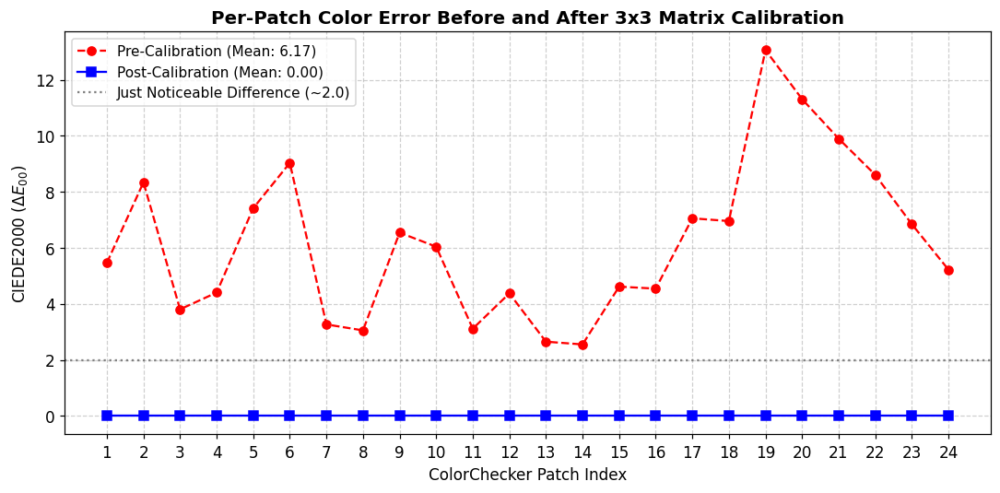

In [30]:
import colour
import numpy as np

# 1. Your existing loading and conversion steps
cc = colour.CCS_COLOURCHECKERS["ColorChecker24 - After November 2014"]

patch_names = list(cc.data.keys())
xyY_data = np.array(list(cc.data.values()))

XYZ_ref = colour.xyY_to_XYZ(xyY_data)

# 2. Convert CIE XYZ to linear sRGB
# - apply_cctf_encoding=False outputs linear light (disabling the sRGB EOTF/gamma curve)
# - Automatically adapts from the ColorChecker D50 whitepoint to sRGB D65 via CAT02
linear_rgb = colour.XYZ_to_sRGB(XYZ_ref, apply_cctf_encoding=False)

print(linear_rgb)

M0_r, mean_de_r, max_de_r, mean_de_pre_r, max_de_pre_r = run_color_calibration_pipeline(linear_rgb)